# Etapa final: modelo POT no estacionario para O$_3$

ESTO ES LO QUE HACE LEAN TODO PORQUE ME ESMERÉ EN PONER EXPLICACIONES DEL CODIGO Y DEL PROYECTO PARA EL CONTEXTO

La probabilidad de superar la norma $c$ se separa en dos partes (Gyarmati-Szabz) la formula esta en el documento de las entregas no la puse porque escribirla es demasiado trabajo así que lean el documento si tienen duda de la formula. 

- zeta se estima con regresión logística.
- sigma y xi son los parámetros de la GPD; sigma depende de las condiciones.

1A ¿Cuánto duran los episodios y qué hace más altos los picos? 
1B ¿Mañana a esta hora se superará u = 63 ppb? 
1C ¿Mañana a esta hora se superará la norma c = 90 ppb? 
2  ¿Qué estaciones comparten episodios extremos? ¿Influye el viento? 

Solo se usan (dado que ricardo nos avisó lol) datos_no_imputados.csv, porque la base imputada tiene lluvia
negativa y aplana las colas. Entrenamiento 2023–2024, validación 2025 (para elegir modelos) y
prueba 2026 (enero–julio, solo para reportar).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
from scipy.optimize import minimize
from scipy.stats import chi2, norm, expon, binomtest
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.metrics import roc_auc_score, brier_score_loss
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")

RUTA_DATOS = "../data/datos_no_imputados.csv"
RUTA_FIGURAS = "../figuras/"

VAR = "O3"   # contaminante
U = 63.0     # umbral del modelo
C = 90.0     # norma de 1 h
H = 24       # horizonte del pronóstico (horas)
R = 24       # longitud de racha para el declustering

COORDS = pd.DataFrame(
    [[25.675833, -100.338333], [25.744722, -100.253056], [25.777222, -100.188056],
     [25.790556, -100.078333], [25.762778, -100.369167], [25.800278, -100.584444],
     [25.768333, -100.463611], [25.798611, -100.327222], [25.729722, -100.310000],
     [25.665278, -100.243611], [25.645833, -100.095278], [25.601111, -99.999167],
     [25.675556, -100.458056], [25.665000, -100.412778], [25.616944, -100.273889]],
    index=["CE", "NE", "NE2", "NE3", "NO", "NO2", "NO3", "NTE", "NTE2",
           "SE", "SE2", "SE3", "SO", "SO2", "SUR"], columns=["lat", "lon"])

# Variables meteorológicas del ACP (las mismas de Etapa3_ACP_Logistica)
MET_ACP = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "WDR_sin", "WDR_cos"]

Datos



In [2]:
def cargar_datos(ruta):
    d = pd.read_csv(ruta, low_memory=False)

    # En 2024 los datos vienen en columnas con unidades, por ejemplo "O3 (ppb)"
    for col in d.columns:
        if " (" in col:
            nombre = col.split(" (")[0]
            d[nombre] = d[nombre].fillna(d[col])

    d["Fecha y hora"] = pd.to_datetime(d["Fecha y hora"])
    d = d[d["Fecha y hora"] >= "2023-01-01"].copy()

    # Factor de la lluvia indicado por el SIMA
    estaciones_x20 = ["CE", "NE", "NO2", "NO3", "NTE2", "SE", "SO"]
    d.loc[d["Estacion"].isin(estaciones_x20), "RAINF"] *= 20

    # Limpieza: valores negativos o imposibles se vuelven faltantes
    for v in ["O3", "SO2", "PM10", "PM2.5", "NO", "NO2", "NOX", "CO",
              "RAINF", "SR", "WSR", "RH", "PRS"]:
        d.loc[d[v] < 0, v] = np.nan
    d.loc[d["RH"] > 105, "RH"] = np.nan
    d["RH"] = d["RH"].clip(upper=100)
    d.loc[(d["TOUT"] < -10) | (d["TOUT"] > 50), "TOUT"] = np.nan
    d.loc[(d["WDR"] < 0) | (d["WDR"] > 360), "WDR"] = np.nan
    d.loc[d["SR"] > 1.5, "SR"] = np.nan
    d.loc[(d["PRS"] < 650) | (d["PRS"] > 780), "PRS"] = np.nan
    d.loc[d["WSR"] > 150, "WSR"] = np.nan
    d.loc[d["RAINF"] > 100, "RAINF"] = np.nan

    columnas = ["Fecha y hora", "Estacion", "O3", "SO2", "PM10", "PM2.5", "NO2", "NOX", "CO",
                "TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "WDR"]
    return d[columnas]


def etiqueta_periodo(fechas):
    fechas = pd.DatetimeIndex(fechas)
    periodo = np.full(len(fechas), "prueba", dtype=object)
    periodo[fechas < "2026-01-01"] = "validación"
    periodo[fechas < "2025-01-01"] = "entrenamiento"
    return periodo


def agregar_variables(s):
    s = s.copy()
    s["RAINF"] = np.log1p(s["RAINF"])               # la lluvia casi siempre es 0
    angulo = np.deg2rad(s["WDR"])
    s["WDR_sin"] = np.sin(angulo)                   # la dirección es circular porque así le das continuidad osea más que nada un viento que va a 1º es lo mismo que uno que va a 181º
    s["WDR_cos"] = np.cos(angulo)
    s["wind_u"] = -s["WSR"] * np.sin(angulo)        # viento hacia el este
    s["wind_v"] = -s["WSR"] * np.cos(angulo)        # viento hacia el norte
    hora = s.index.hour
    mes = s.index.month
    s["hora_sen1"] = np.sin(2 * np.pi * hora / 24)
    s["hora_cos1"] = np.cos(2 * np.pi * hora / 24)
    s["hora_sen2"] = np.sin(4 * np.pi * hora / 24)
    s["hora_cos2"] = np.cos(4 * np.pi * hora / 24)
    s["mes_sen"] = np.sin(2 * np.pi * (mes - 1) / 12)
    s["mes_cos"] = np.cos(2 * np.pi * (mes - 1) / 12)
    s["periodo"] = etiqueta_periodo(s.index)
    return s


def construir_estaciones(df):
    # Cada estación se pone en una malla horaria completa: una fila = una hora
    horas = pd.date_range(df["Fecha y hora"].min(), df["Fecha y hora"].max(), freq="h")
    crudos = {}
    for nombre in sorted(df["Estacion"].unique()):
        s = df[df["Estacion"] == nombre].drop(columns="Estacion")
        s = s.set_index("Fecha y hora").sort_index()
        s = s[~s.index.duplicated()]
        crudos[nombre] = s.reindex(horas)

    # Marcamos las horas con toda la meteorología medida (el ACP solo usa estas)
    meteo = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF"]
    for s in crudos.values():
        s["met_observada"] = s[meteo + ["WDR"]].notna().all(axis=1)

    # Huecos de meteorología: mediana de las demás estaciones a la misma hora.
    # El ozono nunca se rellena.
    relleno = {}
    for nombre in crudos:
        relleno[nombre] = {}
    for v in meteo:
        tabla = pd.DataFrame({n: crudos[n][v] for n in crudos})
        mediana_ciudad = tabla.median(axis=1)
        for n in crudos:
            relleno[n][v] = crudos[n][v].isna().mean()
            crudos[n][v] = crudos[n][v].fillna(mediana_ciudad)

    # La dirección del viento se rellena con la dirección del viento promedio
    seno = pd.DataFrame({n: np.sin(np.deg2rad(crudos[n]["WDR"])) for n in crudos}).mean(axis=1)
    coseno = pd.DataFrame({n: np.cos(np.deg2rad(crudos[n]["WDR"])) for n in crudos}).mean(axis=1)
    direccion_ciudad = (np.degrees(np.arctan2(seno, coseno)) + 360) % 360
    for n in crudos:
        relleno[n]["WDR"] = crudos[n]["WDR"].isna().mean()
        crudos[n]["WDR"] = crudos[n]["WDR"].fillna(direccion_ciudad)

    E = {}
    for n in crudos:
        E[n] = {"datos": agregar_variables(crudos[n]), "relleno": relleno[n]}
    return E

Verificar la lluvia negativa


In [3]:
import os
if os.path.exists("../data/datos_imputados.csv"):
    imp = pd.read_csv("../data/datos_imputados.csv", low_memory=False)
    for col in imp.select_dtypes("number").columns:
        negativos = (imp[col] < 0).sum()
        if negativos > 0:
            print(f"{col}: {negativos} negativos ({100 * negativos / imp[col].notna().sum():.1f} %)")
    del imp
else:
    print("No está datos_imputados.csv en data/ (no se necesita para este notebook).")

CO: 98 negativos (0.0 %)
NO: 5866 negativos (0.7 %)
NO2: 3549 negativos (0.4 %)
NOX: 668 negativos (0.1 %)
O3: 17 negativos (0.0 %)
RAINF: 128384 negativos (15.4 %)
SR: 148219 negativos (17.8 %)
TOUT: 1363 negativos (0.2 %)
WDR: 270 negativos (0.0 %)


Carga y diccionario por estación


In [4]:
df = cargar_datos(RUTA_DATOS)
E = construir_estaciones(df)
ESTACIONES = list(E.keys())

filas = []
for st in ESTACIONES:
    s = E[st]["datos"]
    fila = {"estación": st}
    for p in ["entrenamiento", "validación", "prueba"]:
        x = s.loc[s["periodo"] == p, VAR]
        fila[f"{p} > 63"] = int((x > U).sum())
        fila[f"{p} > 90"] = int((x > C).sum())
    filas.append(fila)
pd.DataFrame(filas).set_index("estación")

,entrenamiento > 63,entrenamiento > 90,validación > 63,validación > 90,prueba > 63,prueba > 90
estación,,,,,,
CE,1178,240,781,174,415,99
NE,585,68,506,71,195,32
NE2,286,43,138,9,66,6
NE3,212,11,353,27,91,8
NO,1051,169,752,148,312,57
NO2,1437,269,982,248,523,109
NO3,997,171,402,46,291,38
NTE,818,108,600,93,364,62
NTE2,636,96,437,76,243,47


Fracción de horas de meteorología rellenadas por estación (2023 a julio de 2026). Destacan la humedad
de NTE (78 %), la temperatura de NE (53 %), la radiación de NO2 (44 %) y la humedad de SO, NO3 y NO
(27–38 %).

In [5]:
pd.DataFrame({st: E[st]["relleno"] for st in ESTACIONES}).T.round(3)

,TOUT,RH,SR,WSR,PRS,RAINF,WDR
CE,0.020,0.024,0.010,0.023,0.021,0.019,0.020
NE,0.527,0.033,0.104,0.031,0.027,0.025,0.026
NE2,0.031,0.051,0.009,0.034,0.036,0.028,0.041
NE3,0.067,0.060,0.135,0.051,0.070,0.037,0.039
NO,0.196,0.272,0.025,0.035,0.037,0.035,0.036
NO2,0.014,0.020,0.438,0.015,0.016,0.014,0.014
NO3,0.087,0.338,0.018,0.082,0.090,0.087,0.016
NTE,0.018,0.784,0.267,0.018,0.023,0.111,0.035
NTE2,0.010,0.015,0.004,0.010,0.011,0.011,0.012
SE,0.018,0.020,0.006,0.019,0.030,0.023,0.018


0.4 ACP de la meteorología
Igual que en Etapa3_ACP_Logistica: matriz de correlación de 8 variables, solo con entrenamiento y
solo con horas medidas (sin relleno). Los puntajes se dividen entre la raíz cuadrada de lambda para que tengan varianza 1.

In [6]:
# Datos de entrenamiento con la meteorología medida, de todas las estaciones
partes = []
for st in ESTACIONES:
    s = E[st]["datos"]
    filtro = (s["periodo"] == "entrenamiento") & s["met_observada"]
    partes.append(s.loc[filtro, MET_ACP])
entrenamiento_met = pd.concat(partes).dropna()

media_met = entrenamiento_met.mean()
desv_met = entrenamiento_met.std()
correlacion = entrenamiento_met.corr().values
valores, vectores = np.linalg.eigh(correlacion)
orden = np.argsort(valores)[::-1]               # de mayor a menor
valores = valores[orden]
vectores = vectores[:, orden]

K = 5
CPS = [f"CP{i + 1}" for i in range(K)]
for st in ESTACIONES:
    s = E[st]["datos"]
    Z = (s[MET_ACP] - media_met) / desv_met
    puntajes = Z.values @ vectores[:, :K] / np.sqrt(valores[:K])
    for i in range(K):
        s[CPS[i]] = puntajes[:, i]

print("Varianza acumulada:", np.round(np.cumsum(valores)[:K] / valores.sum(), 3))
cargas = pd.DataFrame(vectores[:, :K] * np.sqrt(valores[:K]), index=MET_ACP, columns=CPS)
cargas.round(2)

Varianza acumulada: [0.286 0.425 0.551 0.674 0.783]


,CP1,CP2,CP3,CP4,CP5
TOUT,-0.79,0.08,-0.05,0.04,-0.09
RH,0.75,-0.24,-0.06,-0.03,0.22
SR,-0.62,0.41,-0.29,-0.22,-0.13
WSR,-0.63,-0.28,-0.09,0.03,0.16
PRS,0.31,0.08,-0.43,-0.80,-0.06
RAINF,0.09,-0.37,-0.78,0.41,-0.27
WDR_sin,-0.44,-0.48,-0.10,-0.20,0.63
WDR_cos,0.18,0.65,-0.34,0.31,0.55


Parte 1A episodios y tamaño de los picos

Bueno esto es general según lo que entedí de la conversación de claude y es que la GPD supone excesos independientes, pero en el ozono no lo son; si a las 15 h se supera u, es muy probable que a las 16 h también. Los excesos llegan en episodios. Con el método de rachas, dos
excesos son del mismo episodio salvo que entre ellos haya al menos r horas por debajo de u. La GPD
se ajusta solo a los picos de los episodios.

Índice extremal: theta = 1 significa sin agrupamiento y theta es aproximadamente el
número de horas arriba de u por episodio.

Funciones de declustering y de la GPD

In [7]:
def declustering(x, u, r):
    # Regresa una tabla con un renglón por episodio
    valores_x = x.to_numpy()
    posiciones = np.where(valores_x > u)[0]
    episodios = []
    actual = []
    for p in posiciones:
        # empieza un episodio nuevo si pasaron al menos r horas sin exceso
        if len(actual) > 0 and p - actual[-1] > r:
            episodios.append(actual)
            actual = []
        actual.append(p)
    if len(actual) > 0:
        episodios.append(actual)

    filas = []
    for ep in episodios:
        pico = ep[np.argmax(valores_x[ep])]
        filas.append({"inicio": x.index[ep[0]], "fin": x.index[ep[-1]], "tamaño": len(ep),
                      "pico": valores_x[pico], "hora_pico": x.index[pico]})
    return pd.DataFrame(filas)


def theta_intervalos(x, u):
    # Estimador de intervalos de Ferro y Segers (2003)
    posiciones = np.where(x.to_numpy() > u)[0]
    N = len(posiciones)
    T = np.diff(posiciones)
    if T.max() <= 2:
        theta = 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum())
    else:
        theta = 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum())
    return min(1.0, theta)


def log1p_entre_xi(xi, z):
    # (1/xi) * log(1 + xi*z); cuando xi = 0 el límite es z
    if abs(xi) < 1e-8:
        return z
    return np.log1p(xi * z) / xi


def gpd_nll(parametros, y, Z):
    # -log verosimilitud de la GPD con log(sigma) = Z , beta y xi constante
    beta = parametros[:-1]
    xi = parametros[-1]
    if xi <= -1:
        return np.inf
    sigma = np.exp(Z @ beta)
    z = y / sigma
    if np.any(1 + xi * z <= 0):        # exceso fuera del soporte
        return np.inf
    return np.sum(np.log(sigma) + (1 + xi) * log1p_entre_xi(xi, z))


def matriz_diseño(datos, covs, media=None, desv=None):
    # Columna de unos + covariables estandarizadas
    if len(covs) == 0:
        return np.ones((len(datos), 1)), None, None
    if media is None:
        media = datos[covs].mean()
        desv = datos[covs].std()
    Zc = ((datos[covs] - media) / desv).to_numpy()
    return np.column_stack([np.ones(len(datos)), Zc]), media, desv


def minimizar(f, x0):
    # Primero Nelder-Mead para acercarse y luego BFGS para afinar
    res1 = minimize(f, x0, method="Nelder-Mead",
                    options={"maxiter": 40000, "xatol": 1e-7, "fatol": 1e-9})
    res2 = minimize(f, res1.x, method="BFGS", options={"gtol": 1e-6})
    if np.isfinite(res2.fun) and res2.fun <= res1.fun:
        return res2
    return res1


def ajustar_gpd(datos, covs, inicio=None):
    # Modelo I: log(sigma) lineal en las covariables, xi constante.
    # datos debe tener la columna "y" con los excesos.
    # inicio: modelo más chico; sus parámetros son el punto de partida (así el
    # modelo grande nunca queda con peor verosimilitud que el chico).
    y = datos["y"].to_numpy()
    Z, media, desv = matriz_diseño(datos, covs)
    f = lambda p: gpd_nll(p, y, Z)

    puntos_iniciales = []
    if inicio is not None:
        anteriores = dict(zip(inicio["nombres"], inicio["params"]))
        x0 = [anteriores.get(n, 0.0) for n in ["intercepto"] + covs] + [anteriores["xi"]]
        puntos_iniciales.append(np.array(x0))
    for xi0 in [0.1, -0.1]:
        x0 = [np.log(y.mean() * (1 - xi0))] + [0.0] * len(covs) + [xi0]
        puntos_iniciales.append(np.array(x0))

    mejor = None
    for x0 in puntos_iniciales:
        if not np.isfinite(f(x0)):
            continue
        res = minimizar(f, x0)
        if mejor is None or res.fun < mejor.fun:
            mejor = res

    return {"params": mejor.x, "nll": mejor.fun, "k": len(mejor.x), "n": len(y),
            "nombres": ["intercepto"] + covs + ["xi"], "covs": covs,
            "media": media, "desv": desv, "Z": Z, "y": y}


def sigma_gpd(m, datos):
    Z, _, _ = matriz_diseño(datos, m["covs"], m["media"], m["desv"])
    return np.exp(Z @ m["params"][:-1])


def prob_mayor_gpd(x, sigma, xi):
    # P(Y > x) para Y ~ GPD(sigma, xi); vale 0 fuera del soporte
    sigma = np.asarray(sigma, dtype=float)
    if abs(xi) < 1e-8:
        return np.exp(-x / sigma)
    t = 1 + xi * x / sigma
    resultado = np.zeros(len(sigma))
    resultado[t > 0] = t[t > 0] ** (-1 / xi)
    return resultado


def hessiana(f, x, eps=1e-4):
    k = len(x)
    Hm = np.zeros((k, k))
    for i in range(k):
        for j in range(i, k):
            ei = np.zeros(k)
            ej = np.zeros(k)
            ei[i] = eps
            ej[j] = eps
            Hm[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * eps ** 2)
            Hm[j, i] = Hm[i, j]
    return Hm


def resumen_gpd(m):
    f = lambda p: gpd_nll(p, m["y"], m["Z"])
    cov = np.linalg.inv(hessiana(f, m["params"]))
    ee = np.sqrt(np.clip(np.diag(cov), 0, None))
    z = m["params"] / ee
    tabla = pd.DataFrame({"coef": m["params"], "ee": ee, "z": z,
                          "p": 2 * (1 - norm.cdf(np.abs(z)))}, index=m["nombres"])
    tabla["exp(coef)"] = np.exp(tabla["coef"])
    tabla.loc["xi", "exp(coef)"] = np.nan
    return tabla


def prueba_rv(chico, grande):
    D = 2 * (chico["nll"] - grande["nll"])
    gl = grande["k"] - chico["k"]
    return D, gl, chi2.sf(D, gl)


def aic(m):
    return 2 * m["nll"] + 2 * m["k"]


def residuales_gpd(m):
    # Si el modelo es correcto, siguen una exponencial(1)
    xi = m["params"][-1]
    sigma = np.exp(m["Z"] @ m["params"][:-1])
    return log1p_entre_xi(xi, m["y"] / sigma)


def nll_por_exceso(m, datos):
    # -log verosimilitud de cada exceso nuevo; infinito si cae fuera del soporte
    y = datos["y"].to_numpy()
    sigma = sigma_gpd(m, datos)
    xi = m["params"][-1]
    z = y / sigma
    resultado = np.full(len(y), np.inf)
    dentro = 1 + xi * z > 0
    resultado[dentro] = np.log(sigma[dentro]) + (1 + xi) * log1p_entre_xi(xi, z[dentro])
    return resultado

In [8]:
# Modelo II de Gyarmati-Szabó et al. (estabilidad del umbral):
#   sigma_u = (alpha(c) + u*beta) * exp(gamma(c))      xi = beta * exp(gamma(c))
def nll_modelo2(parametros, y, Z, u):
    p = Z.shape[1]
    alpha = parametros[:p]
    beta = parametros[p]
    gamma = parametros[p + 1:]
    if p > 1:
        e_gamma = np.exp(Z[:, 1:] @ gamma)
    else:
        e_gamma = np.ones(len(y))
    sigma = (Z @ alpha + u * beta) * e_gamma
    xi = beta * e_gamma
    if np.any(sigma <= 0) or np.any(xi <= -1):
        return np.inf
    z = y / sigma
    if np.any(1 + xi * z <= 0):
        return np.inf
    if abs(beta) < 1e-8:
        return np.sum(np.log(sigma) + z)
    return np.sum(np.log(sigma) + (1 + 1 / xi) * np.log1p(xi * z))


def ajustar_modelo2(datos, covs, u, m0):
    y = datos["y"].to_numpy()
    Z, _, _ = matriz_diseño(datos, covs)
    xi0 = m0["params"][-1]
    sigma0 = np.exp(m0["params"][0])
    x0 = np.concatenate([[sigma0 - u * xi0], np.zeros(len(covs)), [xi0], np.zeros(len(covs))])
    res = minimizar(lambda p: nll_modelo2(p, y, Z, u), x0)
    return {"nll": res.fun, "k": len(res.x)}

 Sensibilidad a r

In [9]:
RS = [3, 6, 12, 24, 48, 72]
for st in ESTACIONES:
    s = E[st]["datos"]
    x = s.loc[s["periodo"] == "entrenamiento", VAR]
    filas = []
    for r in RS:
        ep = declustering(x, U, r)
        m = ajustar_gpd(pd.DataFrame({"y": ep["pico"].to_numpy() - U}), [])
        filas.append({"r": r, "episodios": len(ep), "theta": len(ep) / (x > U).sum(),
                      "xi": m["params"][-1], "sigma": np.exp(m["params"][0])})
    E[st]["sensibilidad"] = pd.DataFrame(filas)

sens = pd.concat([E[st]["sensibilidad"] for st in ESTACIONES])
sens.groupby("r").median().round(3)

,episodios,theta,xi,sigma
r,,,,
3,244.0,0.290,-0.107,20.025
6,244.0,0.287,-0.108,20.253
12,244.0,0.287,-0.108,20.253
24,98.0,0.128,-0.139,23.258
48,65.0,0.089,-0.210,28.411
72,51.0,0.073,-0.201,28.637


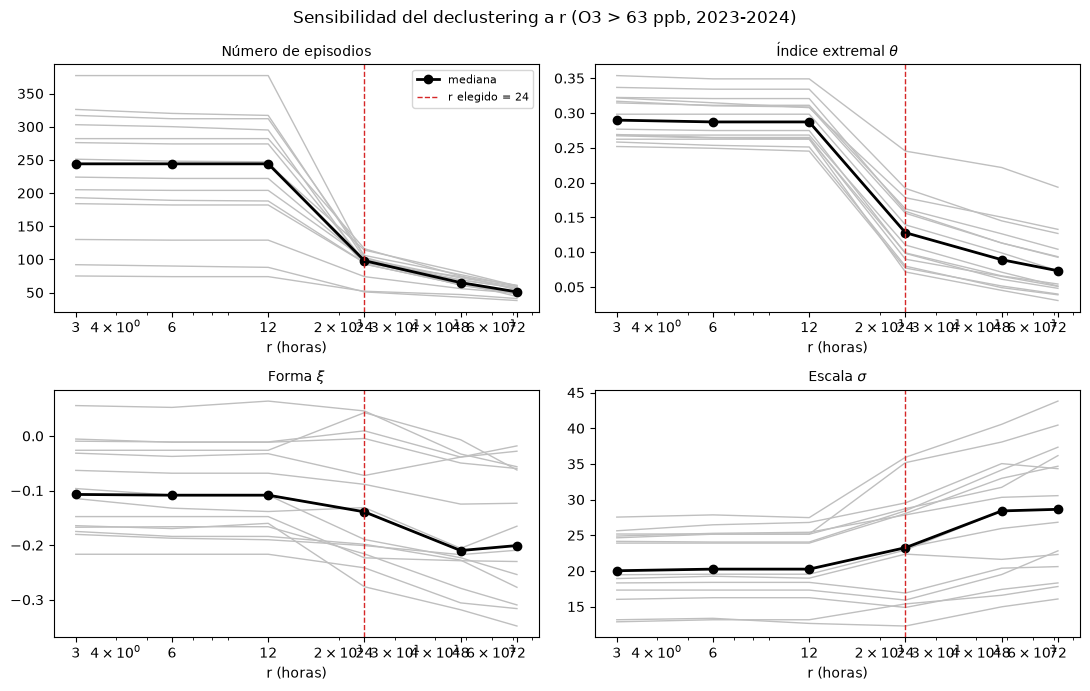

In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
columnas = ["episodios", "theta", "xi", "sigma"]
titulos = ["Número de episodios", r"Índice extremal $\theta$", r"Forma $\xi$", r"Escala $\sigma$"]
for eje, col, titulo in zip(ejes.flat, columnas, titulos):
    for st in ESTACIONES:
        eje.plot(E[st]["sensibilidad"]["r"], E[st]["sensibilidad"][col], color="0.75", lw=1)
    mediana = sens.groupby("r")[col].median()
    eje.plot(mediana.index, mediana.values, "o-", color="black", lw=2, label="mediana")
    eje.axvline(R, color="tab:red", ls="--", lw=1, label=f"r elegido = {R}")
    eje.set_xscale("log")
    eje.set_xticks(RS)
    eje.set_xticklabels(RS)
    eje.set_xlabel("r (horas)")
    eje.set_title(titulo, fontsize=10)
ejes[0, 0].legend(fontsize=8)
fig.suptitle(f"Sensibilidad del declustering a r ({VAR} > {U:.0f} ppb, 2023-2024)")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_sensibilidad_r.png", dpi=200)
plt.show()

 Con r entre 3 y 12 h los resultados son idénticos: la noche siempre separa los episodios,
porque el ozono se forma con el sol. Con r = 24 h se unen tardes de días seguidos (aire estancado
varios días) y theta baja. Se usa r = 24 h para que dos tardes seguidas no cuenten como
independientes; xi cambia poco entre 12 y 24 h.

In [11]:
filas = []
for st in ESTACIONES:
    s = E[st]["datos"]
    x = s.loc[s["periodo"] == "entrenamiento", VAR]
    ep = declustering(x, U, R)
    ep_tarde = declustering(x, U, 12)
    duracion = (ep["fin"] - ep["inicio"]).dt.total_seconds() / 3600 + 1
    filas.append({"estación": st, "excesos": int((x > U).sum()), "episodios (r=24)": len(ep),
                  "theta rachas": len(ep) / (x > U).sum(),
                  "theta intervalos": theta_intervalos(x, U),
                  "horas > u por tarde": ep_tarde["tamaño"].mean(),
                  "horas > u por episodio": ep["tamaño"].mean(),
                  "duración media (h)": duracion.mean(), "duración máx (h)": duracion.max()})
pd.DataFrame(filas).set_index("estación").round(2)

,excesos,episodios (r=24),theta rachas,theta intervalos,horas > u por tarde,horas > u por episodio,duración media (h),duración máx (h)
estación,,,,,,,,
CE,1178,106,0.09,0.19,3.78,11.11,49.31,438.0
NE,585,95,0.16,0.19,3.21,6.16,24.31,291.0
NE2,286,51,0.18,0.12,3.25,5.61,20.51,222.0
NE3,212,52,0.25,0.22,2.86,4.08,12.50,103.0
NO,1051,116,0.11,0.16,3.73,9.06,36.92,335.0
NO2,1437,103,0.07,0.11,3.81,13.95,66.54,532.0
NO3,997,98,0.10,0.07,3.64,10.17,45.87,479.0
NTE,818,114,0.14,0.21,3.35,7.18,29.75,362.0
NTE2,636,101,0.16,0.23,3.12,6.30,26.68,290.0


GPD con covariables en los picos (Modelo I)


In [12]:
MET_GPD = ["WSR", "TOUT", "RH"]
HORA = ["hora_sen1", "hora_cos1"]

for st in ESTACIONES:
    s = E[st]["datos"]
    x = s.loc[s["periodo"] == "entrenamiento", VAR]
    ep = declustering(x, U, R)
    picos = s.loc[ep["hora_pico"]].copy()
    picos["y"] = ep["pico"].to_numpy() - U
    picos = picos.dropna(subset=MET_GPD + HORA + CPS)
    E[st]["picos"] = picos

    m0 = ajustar_gpd(picos, [])
    m1 = ajustar_gpd(picos, MET_GPD, inicio=m0)
    m2 = ajustar_gpd(picos, MET_GPD + HORA, inicio=m1)
    m3 = ajustar_gpd(picos, CPS, inicio=m0)
    mII = ajustar_modelo2(picos, MET_GPD, U, m0)
    E[st]["gpd_picos"] = {"m0": m0, "m1": m1, "m2": m2, "m3": m3, "II": mII}

filas = []
for st in ESTACIONES:
    g = E[st]["gpd_picos"]
    fila = {"estación": st, "picos": g["m0"]["n"], "xi (m0)": g["m0"]["params"][-1]}
    for nombre, chico, grande in [("m1 vs m0", "m0", "m1"), ("m2 vs m1", "m1", "m2"), ("m3 vs m0", "m0", "m3")]:
        D, gl, p = prueba_rv(g[chico], g[grande])
        fila["D " + nombre] = D
        fila["p " + nombre] = p
    for k in ["m0", "m1", "m2", "m3", "II"]:
        fila["AIC " + k] = aic(g[k])
    fila["mejor AIC"] = min(["m0", "m1", "m2", "m3", "II"], key=lambda k: aic(g[k]))
    filas.append(fila)
pruebas_picos = pd.DataFrame(filas).set_index("estación")
print("Modelo con menor AIC:", pruebas_picos["mejor AIC"].value_counts().to_dict())
print("¿Alguna D negativa?:", (pruebas_picos.filter(like="D ") < -1e-6).any().any())
pruebas_picos.round(3)

Modelo con menor AIC: {'m2': 8, 'm3': 5, 'm0': 1, 'II': 1}
¿Alguna D negativa?: False


,picos,xi (m0),D m1 vs m0,p m1 vs m0,D m2 vs m1,p m2 vs m1,D m3 vs m0,p m3 vs m0,AIC m0,AIC m1,AIC m2,AIC m3,AIC II,mejor AIC
estación,,,,,,,,,,,,,,
CE,106,-0.198,46.796,0.000,5.531,0.063,58.464,0.000,885.801,845.006,843.475,837.338,862.526,m3
NE,95,-0.005,8.685,0.034,11.070,0.004,14.305,0.014,706.112,703.427,696.357,701.807,699.400,m2
NE2,51,0.046,3.551,0.314,10.521,0.005,4.471,0.484,366.437,368.886,362.365,371.966,372.786,m2
NE3,52,-0.190,2.691,0.442,5.567,0.062,8.581,0.127,372.471,375.780,374.213,373.891,375.966,m0
NO,116,-0.241,22.091,0.000,4.305,0.116,31.585,0.000,953.481,937.391,937.085,931.896,938.049,m3
NO2,103,-0.223,23.923,0.000,7.301,0.026,13.186,0.022,897.483,879.560,876.260,894.297,882.302,m2
NO3,98,-0.216,16.945,0.001,9.186,0.010,12.375,0.030,813.798,802.853,797.667,811.423,810.210,m2
NTE,114,0.043,18.906,0.000,9.027,0.011,31.818,0.000,872.648,859.742,854.715,850.830,858.330,m3
NTE2,101,0.009,22.676,0.000,3.592,0.166,29.768,0.000,779.004,762.328,762.737,759.236,766.911,m3


In [13]:
# Coeficientes de m1 en SUR
resumen_gpd(E["SUR"]["gpd_picos"]["m1"]).round(3)

,coef,ee,z,p,exp(coef)
intercepto,3.482,0.126,27.672,0.000,32.525
WSR,-0.196,0.073,-2.688,0.007,0.822
TOUT,0.396,0.055,7.237,0.000,1.486
RH,-0.221,0.072,-3.081,0.002,0.802
xi,-0.522,0.090,-5.833,0.000,NaN


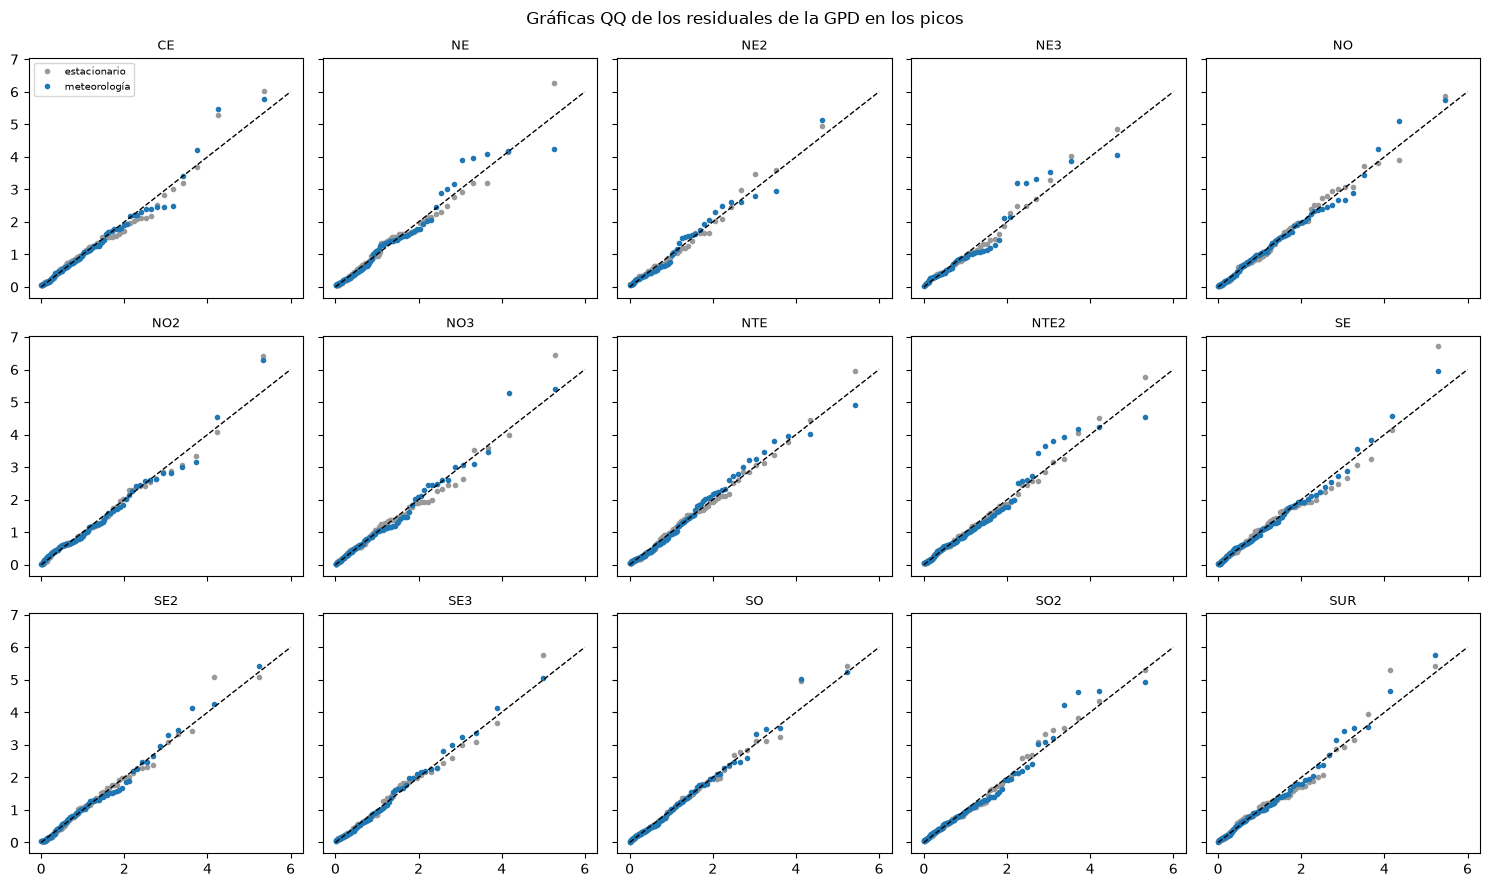

In [14]:
# Gráficas QQ de los residuales contra una exponencial(1)
fig, ejes = plt.subplots(3, 5, figsize=(15, 9), sharex=True, sharey=True)
for eje, st in zip(ejes.flat, ESTACIONES):
    for k, color, etiqueta in [("m0", "0.6", "estacionario"), ("m1", "tab:blue", "meteorología")]:
        res = np.sort(residuales_gpd(E[st]["gpd_picos"][k]))
        q = expon.ppf((np.arange(1, len(res) + 1) - 0.5) / len(res))
        eje.plot(q, res, "o", ms=3, color=color, label=etiqueta)
    eje.plot([0, 6], [0, 6], "k--", lw=1)
    eje.set_title(st, fontsize=9)
ejes[0, 0].legend(fontsize=7)
fig.suptitle("Gráficas QQ de los residuales de la GPD en los picos")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_qq_picos.png", dpi=200)
plt.show()

In [15]:
# Escenarios en SUR: una covariable en su percentil 10 o 90, las demás en la mediana
m = E["SUR"]["gpd_picos"]["m1"]
p = E["SUR"]["picos"]
xi = m["params"][-1]
base = {c: p[c].median() for c in MET_GPD}

filas = [dict(base, escenario="todas en la mediana")]
for c in MET_GPD:
    for q in [0.1, 0.9]:
        fila = dict(base, escenario=f"{c} en el percentil {int(q * 100)}")
        fila[c] = p[c].quantile(q)
        filas.append(fila)
escenarios = pd.DataFrame(filas).set_index("escenario")
sig = sigma_gpd(m, escenarios)
escenarios["sigma"] = sig
escenarios["percentil 95 del pico (ppb)"] = U + sig / xi * (0.05 ** (-xi) - 1)
escenarios["P(pico > 90)"] = prob_mayor_gpd(C - U, sig, xi)
escenarios.round(2)

,WSR,TOUT,RH,sigma,percentil 95 del pico (ppb),P(pico > 90)
escenario,,,,,,
todas en la mediana,7.10,32.18,37.0,34.63,115.45,0.37
WSR en el percentil 10,5.62,32.18,37.0,39.02,122.09,0.42
WSR en el percentil 90,11.00,32.18,37.0,25.29,101.30,0.21
TOUT en el percentil 10,7.10,27.25,37.0,23.47,98.54,0.17
TOUT en el percentil 90,7.10,36.93,37.0,50.38,139.30,0.53
RH en el percentil 10,7.10,32.18,19.2,49.27,137.62,0.52
RH en el percentil 90,7.10,32.18,50.0,26.77,103.54,0.24


Parte 1B: regresión logística para 

Cada fila usa lo que se sabe en la hora t para predecir la hora t + 24, osea la misma hora de mañana.


Persistencia: x_t (nivel actual), max24, n_exc24 y n_exc168 (horas > 63 en 24 h y 7 días) 
Calendario: hora y mes de la hora objetivo 
Meteorología  8 variables originales o CP1–CP5 



In [16]:
def tabla_pronostico(s, h):
    x = s[VAR]
    d = pd.DataFrame(index=s.index)
    d["x_futuro"] = x.shift(-h)                       # lo que pasa en t + h
    d["y"] = np.where(d["x_futuro"].isna(), np.nan, (d["x_futuro"] > U).astype(float))
    exceso = (x > U).astype(float).where(x.notna())
    d["x_t"] = x
    d["max24"] = x.rolling(24, min_periods=12).max()
    d["n_exc24"] = exceso.rolling(24, min_periods=12).sum()
    d["n_exc168"] = exceso.rolling(168, min_periods=84).sum()
    for c in ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "wind_u", "wind_v"] + CPS:
        d[c] = s[c]
    objetivo = s.index + pd.Timedelta(hours=h)        # hora que se predice
    d["hora_sen1"] = np.sin(2 * np.pi * objetivo.hour / 24)
    d["hora_cos1"] = np.cos(2 * np.pi * objetivo.hour / 24)
    d["hora_sen2"] = np.sin(4 * np.pi * objetivo.hour / 24)
    d["hora_cos2"] = np.cos(4 * np.pi * objetivo.hour / 24)
    d["mes_sen"] = np.sin(2 * np.pi * (objetivo.month - 1) / 12)
    d["mes_cos"] = np.cos(2 * np.pi * (objetivo.month - 1) / 12)
    d["periodo"] = etiqueta_periodo(objetivo)
    d["fecha_objetivo"] = objetivo.normalize()
    return d


def ajustar_logit(datos, variables):
    datos = datos.dropna(subset=variables + ["y"])
    # quitamos variables constantes (estaciones sin pluviómetro: lluvia siempre 0)
    variables = [v for v in variables if datos[v].std() > 1e-9]
    media = datos[variables].mean()
    desv = datos[variables].std()
    X = sm.add_constant((datos[variables] - media) / desv)
    dias = pd.factorize(datos["fecha_objetivo"])[0]
    res = sm.Logit(datos["y"], X).fit(disp=0, maxiter=200, cov_type="cluster",
                                      cov_kwds={"groups": dias})
    return {"res": res, "media": media, "desv": desv, "variables": variables}


def predecir_logit(m, datos):
    X = sm.add_constant((datos[m["variables"]] - m["media"]) / m["desv"], has_constant="add")
    return m["res"].predict(X)


def metricas(y, p, p_ref=None):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    ok = ~(np.isnan(y) | np.isnan(p))
    resultado = {"n": int(ok.sum()), "eventos": int(y[ok].sum()),
                 "brier": brier_score_loss(y[ok], p[ok]), "auc": roc_auc_score(y[ok], p[ok])}
    if p_ref is not None:
        ref = np.asarray(p_ref, dtype=float)[ok]
        resultado["bss"] = 1 - resultado["brier"] / brier_score_loss(y[ok], ref)
    return resultado


def calibracion(y, p, cortes):
    t = pd.DataFrame({"y": y, "p": p}).dropna()
    grupos = t.groupby(pd.cut(t["p"], cortes, include_lowest=True), observed=True)
    tabla = grupos.agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    return tabla[tabla["n"] >= 30]


def juntar(periodo, columnas):
    # Junta las filas de un periodo de todas las estaciones
    partes = []
    for st in ESTACIONES:
        d = E[st]["pron"]
        parte = d.loc[d["periodo"] == periodo, columnas].copy()
        parte["estacion"] = st
        partes.append(parte)
    return pd.concat(partes)

In [17]:
PERS = ["x_t", "max24", "n_exc24", "n_exc168"]
CAL = ["hora_sen1", "hora_cos1", "hora_sen2", "hora_cos2", "mes_sen", "mes_cos"]
METR = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "wind_u", "wind_v"]
CONJUNTOS = {"persistencia": PERS,
             "+ calendario": PERS + CAL,
             "+ calendario + meteorología": PERS + CAL + METR,
             "+ calendario + ACP": PERS + CAL + CPS}
TODAS = sorted(set(PERS + CAL + METR + CPS))

for st in ESTACIONES:
    d = tabla_pronostico(E[st]["datos"], H)
    d = d.dropna(subset=TODAS + ["y"])                 # mismas filas para todos los modelos
    entrenamiento = d[d["periodo"] == "entrenamiento"]
    clima = entrenamiento.groupby(entrenamiento.index.hour)["y"].mean()
    d["ref_u"] = d.index.hour.map(clima)
    E[st]["logit"] = {}
    for nombre, variables in CONJUNTOS.items():
        m = ajustar_logit(entrenamiento, variables)
        E[st]["logit"][nombre] = m
        d["p_" + nombre] = predecir_logit(m, d)
    E[st]["pron"] = d

filas = []
for per in ["validación", "prueba"]:
    t = juntar(per, ["y", "ref_u"] + ["p_" + k for k in CONJUNTOS])
    filas.append({"periodo": per, "modelo": "climatología", **metricas(t["y"], t["ref_u"], t["ref_u"])})
    for k in CONJUNTOS:
        filas.append({"periodo": per, "modelo": k, **metricas(t["y"], t["p_" + k], t["ref_u"])})
pd.DataFrame(filas).set_index(["periodo", "modelo"]).round(4)

n  eventos   brier     auc  \
periodo    modelo                                                         
validación climatología                 118077     8396  0.0536  0.9073   
           persistencia                 118077     8396  0.0483  0.9212   
           + calendario                 118077     8396  0.0453  0.9408   
           + calendario + meteorología  118077     8396  0.0451  0.9395   
           + calendario + ACP           118077     8396  0.0451  0.9404   
prueba     climatología                  72357     3886  0.0413  0.9160   
           persistencia                  72357     3886  0.0379  0.9263   
           + calendario                  72357     3886  0.0360  0.9436   
           + calendario + meteorología   72357     3886  0.0359  0.9422   
           + calendario + ACP            72357     3886  0.0359  0.9421   

                                           bss  
periodo    modelo                               
validación climatología                 0.0000  
           persistencia                 0.0983  
           + calendario                 0.1537  
           + calendario + meteorología  0.1569  
           + calendario + ACP           0.1571  
prueba     climatología                 0.0000  
           persistencia                 0.0813  
           + calendario                 0.1282  
           + calendario + meteorología  0.1299  
           + calendario + ACP           0.1317

In [18]:
#Prueba de razón de verosimilitudes por estación
filas = []
for st in ESTACIONES:
    L = E[st]["logit"]
    for bloque, chico, grande in [("calendario", "persistencia", "+ calendario"),
                                  ("meteorología", "+ calendario", "+ calendario + meteorología"),
                                  ("ACP", "+ calendario", "+ calendario + ACP")]:
        D = 2 * (L[grande]["res"].llf - L[chico]["res"].llf)
        gl = L[grande]["res"].df_model - L[chico]["res"].df_model
        filas.append({"estación": st, "bloque": bloque, "D": D, "p": chi2.sf(D, gl),
                      "mejora AIC": L[grande]["res"].aic < L[chico]["res"].aic})
bloques = pd.DataFrame(filas)
bloques.groupby("bloque").agg(D_total=("D", "sum"),
                              estaciones_p05=("p", lambda p: int((p < 0.05).sum())),
                              estaciones_mejora_AIC=("mejora AIC", "sum"))

,D_total,estaciones_p05,estaciones_mejora_AIC
bloque,,,
ACP,391.477316,13,13
calendario,6272.844726,15,15
meteorología,601.546866,15,15


Supuesto de linealidad en el logit


In [19]:
CONT = ["x_t", "max24", "n_exc24", "n_exc168"] + CPS
CUAD = [c + "^2" for c in CONT]
BASE = CONJUNTOS["+ calendario + ACP"]

filas = []
significativos = {c: 0 for c in CONT}
for st in ESTACIONES:
    d = E[st]["pron"]
    es_ent = d["periodo"] == "entrenamiento"
    for c in CONT:
        z = (d[c] - d.loc[es_ent, c].mean()) / d.loc[es_ent, c].std()
        d[c + "^2"] = z ** 2
    m_lineal = E[st]["logit"]["+ calendario + ACP"]
    m_cuad = ajustar_logit(d[es_ent], BASE + CUAD)
    E[st]["logit"]["+ cuadrados"] = m_cuad
    d["p_+ cuadrados"] = predecir_logit(m_cuad, d)
    D = 2 * (m_cuad["res"].llf - m_lineal["res"].llf)
    gl = m_cuad["res"].df_model - m_lineal["res"].df_model
    filas.append({"estación": st, "D": D, "p": chi2.sf(D, gl),
                  "AIC lineal": m_lineal["res"].aic, "AIC con cuadrados": m_cuad["res"].aic})
    for c in CONT:
        if c + "^2" in m_cuad["res"].pvalues and m_cuad["res"].pvalues[c + "^2"] < 0.05:
            significativos[c] += 1

lin = pd.DataFrame(filas).set_index("estación")
print("Estaciones donde los cuadrados bajan el AIC:", int((lin["AIC con cuadrados"] < lin["AIC lineal"]).sum()), "de 15")
print("Estaciones donde cada cuadrado es significativo:", significativos)

filas = []
for per in ["validación", "prueba"]:
    t = juntar(per, ["y", "ref_u", "p_+ calendario + ACP", "p_+ cuadrados"])
    filas.append({"periodo": per, "modelo": "lineal", **metricas(t["y"], t["p_+ calendario + ACP"], t["ref_u"])})
    filas.append({"periodo": per, "modelo": "con cuadrados", **metricas(t["y"], t["p_+ cuadrados"], t["ref_u"])})
pd.DataFrame(filas).set_index(["periodo", "modelo"])[["brier", "bss", "auc"]].round(4)

Estaciones donde los cuadrados bajan el AIC: 15 de 15
Estaciones donde cada cuadrado es significativo: {'x_t': 12, 'max24': 1, 'n_exc24': 4, 'n_exc168': 6, 'CP1': 1, 'CP2': 5, 'CP3': 2, 'CP4': 2, 'CP5': 1}


brier     bss     auc
periodo    modelo                               
validación lineal         0.0451  0.1571  0.9404
           con cuadrados  0.0443  0.1726  0.9391
prueba     lineal         0.0359  0.1317  0.9421
           con cuadrados  0.0356  0.1368  0.9433

La linealidad no se cumple del todo, ya que en el cuadrado del nivel actual x_t es significativo
en 12 de 15 estaciones y los cuadrados bajan el AIC en todas. Para zeta mejoran un poco 
(BSS de 0.157 a 0.173 en 2025). Pero para el objetivo final, P(X > 90), el modelo con cuadrados es
peor en 2025 (tabla de la Parte 1C), así que el modelo final se queda lineal.

Demás supuestos: 
 Multicolinealidad= VIF de cada variable.
Independencia: autocorrelación de los residuales de Pearson con la hora anterior y el día anterior;
  y cuánto crecen los errores estándar robustos frente a los normales.
Observaciones influyentes:distancia de Cook



In [20]:
filas = []
for st in ESTACIONES:
    d = E[st]["pron"]
    m = E[st]["logit"]["+ calendario + ACP"]
    ent = d[d["periodo"] == "entrenamiento"].dropna(subset=m["variables"] + ["y"])
    X = sm.add_constant((ent[m["variables"]] - m["media"]) / m["desv"])

    # VIF (sin la constante)
    vif = {}
    for i in range(1, X.shape[1]):
        vif[X.columns[i]] = variance_inflation_factor(X.values, i)
    vif = pd.Series(vif)

    # Residuales de Pearson y autocorrelación en la malla horaria
    p_hat = m["res"].predict(X)
    r = (ent["y"] - p_hat) / np.sqrt(p_hat * (1 - p_hat))
    r_malla = r.reindex(pd.date_range(r.index.min(), r.index.max(), freq="h"))
    m_normal = sm.Logit(ent["y"], X).fit(disp=0)
    razon_ee = (m["res"].bse / m_normal.bse).drop("const").median()

    # distancia de Cook
    w = (p_hat * (1 - p_hat)).to_numpy()
    Xv = X.to_numpy()
    inversa = np.linalg.inv(Xv.T @ (Xv * w[:, None]))
    h = w * np.sum((Xv @ inversa) * Xv, axis=1)
    cook = r.to_numpy() ** 2 * h / (Xv.shape[1] * (1 - h) ** 2)
    E[st]["cook"] = pd.Series(cook, index=ent.index)

    grandes = r.abs() > 3
    filas.append({"estación": st, "VIF máx": vif.max(), "variable": vif.idxmax(),
                  "autocorr 1 h": r_malla.autocorr(1), "autocorr 24 h": r_malla.autocorr(24),
                  "ee robusto / normal": razon_ee, "|r| > 3": int(grandes.sum()),
                  "% de esos que son excesos": 100 * ent.loc[grandes, "y"].mean(),
                  "Cook > 4/n": int((cook > 4 / len(ent)).sum()), "Cook > 1": int((cook > 1).sum()),
                  "Cook máx": cook.max()})
pd.DataFrame(filas).set_index("estación").round(3)

,VIF máx,variable,autocorr 1 h,autocorr 24 h,ee robusto / normal,|r| > 3,% de esos que son excesos,Cook > 4/n,Cook > 1,Cook máx
estación,,,,,,,,,,
CE,4.159,CP1,0.504,-0.000,1.621,140,92.143,983,0,0.167
NE,3.533,CP1,0.132,-0.002,1.621,162,99.383,674,0,0.242
NE2,14.439,CP2,0.464,-0.035,1.253,83,98.795,351,0,0.030
NE3,4.858,CP1,0.521,-0.037,1.540,115,100.000,292,0,0.054
NO,3.823,max24,0.455,-0.015,1.441,111,97.297,889,0,0.046
NO2,3.824,max24,0.499,0.012,1.572,91,82.418,1078,0,0.142
NO3,9.451,CP3,0.479,-0.001,1.621,93,96.774,935,0,0.025
NTE,18.223,CP3,0.283,-0.005,1.783,142,99.296,868,0,0.082
NTE2,4.117,CP1,0.374,-0.012,1.148,119,96.639,702,0,0.043


In [21]:
# ¿Cambian los resultados si quitamos el 1 % de horas más influyentes?
for st in ESTACIONES:
    d = E[st]["pron"]
    m = E[st]["logit"]["+ calendario + ACP"]
    ent = d[d["periodo"] == "entrenamiento"].dropna(subset=m["variables"] + ["y"])
    quitar = E[st]["cook"].nlargest(int(0.01 * len(ent))).index
    m_sin = ajustar_logit(ent.drop(quitar), m["variables"])
    d["p_sin_influyentes"] = predecir_logit(m_sin, d)
    E[st]["coef_sin_influyentes"] = m_sin["res"].params

print(pd.DataFrame({"con todas": E["SUR"]["logit"]["+ calendario + ACP"]["res"].params,
                    "sin el 1 %": E["SUR"]["coef_sin_influyentes"]}).round(3).T.to_string())
filas = []
for per in ["validación", "prueba"]:
    t = juntar(per, ["y", "ref_u", "p_+ calendario + ACP", "p_sin_influyentes"])
    filas.append({"periodo": per, "modelo": "con todas", **metricas(t["y"], t["p_+ calendario + ACP"], t["ref_u"])})
    filas.append({"periodo": per, "modelo": "sin el 1 %", **metricas(t["y"], t["p_sin_influyentes"], t["ref_u"])})
pd.DataFrame(filas).set_index(["periodo", "modelo"])[["brier", "bss", "auc"]].round(4)

             const    x_t  max24  n_exc24  n_exc168  hora_sen1  hora_cos1  hora_sen2  hora_cos2  mes_sen  mes_cos    CP1    CP2    CP3    CP4    CP5
con todas   -7.043  1.019  0.008   -0.056     0.320     -2.899     -2.396     -0.487      0.604   -0.014   -0.238 -0.005  0.010  0.271  0.121 -0.031
sin el 1 % -22.913  1.360 -0.145   -0.089     0.357    -12.927    -13.552     -4.827      0.151   -0.043   -0.239 -0.053  0.028  0.264  0.067 -0.089


brier     bss     auc
periodo    modelo                            
validación con todas   0.0451  0.1571  0.9404
           sin el 1 %  0.0470  0.1224  0.9336
prueba     con todas   0.0359  0.1317  0.9421
           sin el 1 %  0.0365  0.1151  0.9371


Multicolinealidad: VIF < 5 en 10 de 15 estaciones. Los más altos (CP3 en SE2, NTE y NO3; CP2 en NE2,
  de 9 a 19) son de estaciones sin pluviómetro funcionando (0 a 4 horas con lluvia en dos años). Ahí
  CP3, que es sobre todo lluvia, queda como combinación de los otros componentes. SE tiene un VIF moderado
  (6.1). Afecta la interpretación de esos coeficientes, no las predicciones.
Independencia: los residuales se correlacionan con la hora anterior (0.13–0.57) pero no con el día
  anterior (≈ 0). Por eso se usan por día (1.1–1.8 veces más grandes).

 82–100 % de las horas con |r| > 3 son excesos que el modelo no anticipó. Ninguna
  hora tiene Cook > 1.

Quitar el 1 % más influyente empeora el modelo, (BSS de 0.157 a 0.122 en 2025).

In [22]:
# Razones de momios en SUR 
res = E["SUR"]["logit"]["+ calendario + ACP"]["res"]
intervalo = np.exp(res.conf_int())
pd.DataFrame({"coef": res.params, "RM": np.exp(res.params), "IC inf": intervalo[0],
              "IC sup": intervalo[1], "p": res.pvalues}).round(3)

,coef,RM,IC inf,IC sup,p
const,-7.043,0.001,0.000,0.005,0.000
x_t,1.019,2.770,2.240,3.425,0.000
max24,0.008,1.008,0.725,1.402,0.963
n_exc24,-0.056,0.945,0.712,1.255,0.697
n_exc168,0.320,1.377,1.122,1.689,0.002
hora_sen1,-2.899,0.055,0.016,0.194,0.000
hora_cos1,-2.396,0.091,0.025,0.332,0.000
hora_sen2,-0.487,0.614,0.329,1.149,0.127
hora_cos2,0.604,1.829,1.413,2.368,0.000
mes_sen,-0.014,0.986,0.828,1.175,0.875


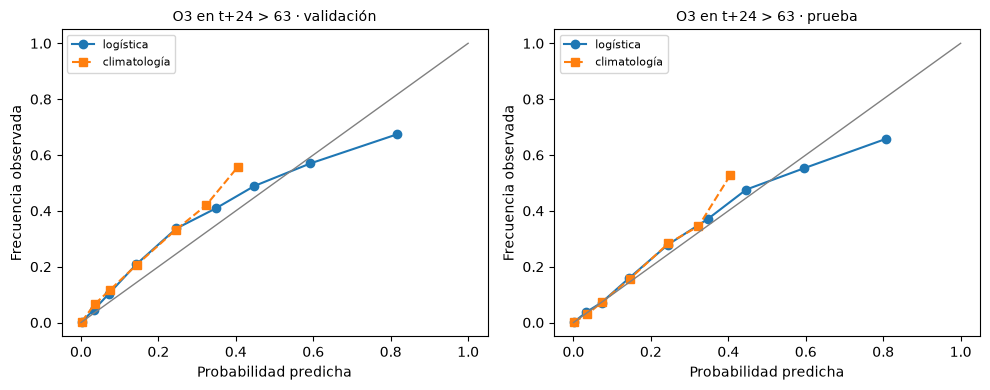

In [23]:
# Calibración de zeta
cortes = [0, .02, .05, .1, .2, .3, .4, .5, .7, 1]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, per in zip(ejes, ["validación", "prueba"]):
    t = juntar(per, ["y", "p_+ calendario + ACP", "ref_u"])
    cal = calibracion(t["y"], t["p_+ calendario + ACP"], cortes)
    eje.plot(cal["pred"], cal["obs"], "o-", label="logística")
    cal = calibracion(t["y"], t["ref_u"], cortes)
    eje.plot(cal["pred"], cal["obs"], "s--", label="climatología")
    eje.plot([0, 1], [0, 1], color="gray", lw=1)
    eje.set_xlabel("Probabilidad predicha")
    eje.set_ylabel("Frecuencia observada")
    eje.set_title(f"O3 en t+24 > {U:.0f} · {per}", fontsize=10)
    eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_calibracion_zeta.png", dpi=200)
plt.show()

Parte 1C



In [36]:
MODELOS_GPD = {"m0": [], "ACP": CPS, "logit ζ": ["logit_zeta"], "ACP + logit ζ": CPS + ["logit_zeta"]}

for st in ESTACIONES:
    d = E[st]["pron"]
    d["zeta"] = d["p_+ calendario + ACP"]
    d["logit_zeta"] = np.log(d["zeta"] / (1 - d["zeta"]))
    excesos = d[d["y"] == 1].copy()
    excesos["y"] = excesos["x_futuro"] - U
    E[st]["excesos"] = excesos
    ent = excesos[excesos["periodo"] == "entrenamiento"]
    m0 = ajustar_gpd(ent, [])
    E[st]["gpd_pron"] = {"m0": m0}
    for nombre, covs in MODELOS_GPD.items():
        if nombre != "m0":
            E[st]["gpd_pron"][nombre] = ajustar_gpd(ent, covs, inicio=m0)

filas = []
for st in ESTACIONES:
    for per in ["validación", "prueba"]:
        nuevos = E[st]["excesos"][E[st]["excesos"]["periodo"] == per]
        nll = {k: nll_por_exceso(m, nuevos) for k, m in E[st]["gpd_pron"].items()}
        comunes = np.ones(len(nuevos), dtype=bool)
        for valores_nll in nll.values():
            comunes = comunes & np.isfinite(valores_nll)
        for k, m in E[st]["gpd_pron"].items():
            filas.append({"estación": st, "periodo": per, "modelo": k, "AIC": aic(m),
                          "nll": nll[k][comunes].sum(),
                          "fuera de soporte": int((~np.isfinite(nll[k])).sum())})
tabla = pd.DataFrame(filas)
resumen = tabla.pivot_table(index="modelo", columns="periodo", values=["nll", "fuera de soporte"], aggfunc="sum")
resumen["AIC (entrenamiento)"] = tabla[tabla["periodo"] == "validación"].groupby("modelo")["AIC"].sum()
resumen.round(1)

fuera de soporte                 nll             \
periodo                 prueba validación   prueba validación   
modelo                                                          
ACP                          7          5  14845.7    32115.4   
ACP + logit ζ               11          7  14713.6    31781.4   
logit ζ                     11          5  14649.9    31433.9   
m0                           0          0  14711.8    31864.4   

              AIC (entrenamiento)  
periodo                            
modelo                             
ACP                       89915.1  
ACP + logit ζ             88822.4  
logit ζ                   88927.8  
m0                        90558.6

In [37]:
# Coeficiente de logit zeta en log(sigma), por estación
filas = []
for st in ESTACIONES:
    m0 = E[st]["gpd_pron"]["m0"]
    mz = E[st]["gpd_pron"]["logit ζ"]
    r = resumen_gpd(mz)
    D, gl, p = prueba_rv(m0, mz)
    filas.append({"estación": st, "excesos": mz["n"], "gamma": r.loc["logit_zeta", "coef"],
                  "exp(gamma)": r.loc["logit_zeta", "exp(coef)"], "xi": r.loc["xi", "coef"],
                  "D vs m0": D, "p": p})
pd.DataFrame(filas).set_index("estación").round(3)

,excesos,gamma,exp(gamma),xi,D vs m0,p
estación,,,,,,
CE,1149,0.316,1.371,-0.249,197.209,0.000
NE,576,0.351,1.421,-0.078,89.066,0.000
NE2,280,0.382,1.465,-0.113,67.245,0.000
NE3,198,0.052,1.053,0.086,0.461,0.497
NO,953,0.270,1.310,-0.174,94.014,0.000
NO2,1413,0.270,1.309,-0.020,126.957,0.000
NO3,974,0.232,1.261,-0.181,94.950,0.000
NTE,797,0.343,1.409,-0.075,108.842,0.000
NTE2,618,0.339,1.404,-0.102,97.132,0.000


In [38]:
for st in ESTACIONES:
    d = E[st]["pron"]
    ent = d[d["periodo"] == "entrenamiento"]
    clima90 = (ent["x_futuro"] > C).groupby(ent.index.hour).mean()
    d["y90"] = (d["x_futuro"] > C).astype(float)
    d["p90_clima"] = d.index.hour.map(clima90)

    ent90 = ent.copy()
    ent90["y"] = (ent90["x_futuro"] > C).astype(float)
    m_directa = ajustar_logit(ent90, BASE)
    d["p90_directa"] = predecir_logit(m_directa, d)

    m0 = E[st]["gpd_pron"]["m0"]
    mz = E[st]["gpd_pron"]["logit ζ"]
    d["p90_sigma_constante"] = d["zeta"] * prob_mayor_gpd(C - U, sigma_gpd(m0, d), m0["params"][-1])
    d["p90_final"] = d["zeta"] * prob_mayor_gpd(C - U, sigma_gpd(mz, d), mz["params"][-1])

    # variante con el zeta del modelo con cuadrados
    zc = d["p_+ cuadrados"]
    d["logit_zeta_c"] = np.log(zc / (1 - zc))
    exc = d[(d["y"] == 1) & (d["periodo"] == "entrenamiento")].copy()
    exc["y"] = exc["x_futuro"] - U
    mc = ajustar_gpd(exc, ["logit_zeta_c"], inicio=m0)
    d["p90_cuadrados"] = zc * prob_mayor_gpd(C - U, sigma_gpd(mc, d), mc["params"][-1])

MODELOS90 = {"climatología": "p90_clima", "logística directa": "p90_directa",
             "dos partes, σ constante": "p90_sigma_constante", "dos partes, σ con logit ζ": "p90_final",
             "dos partes, σ con logit ζ (ζ con cuadrados)": "p90_cuadrados"}
filas = []
for per in ["validación", "prueba"]:
    t = juntar(per, ["y90"] + list(MODELOS90.values()))
    for nombre, col in MODELOS90.items():
        filas.append({"periodo": per, "modelo": nombre, **metricas(t["y90"], t[col], t["p90_clima"])})
pd.DataFrame(filas).set_index(["periodo", "modelo"]).round(4)

n  eventos  \
periodo    modelo                                                         
validación climatología                                 118077     1610   
           logística directa                            118077     1610   
           dos partes, σ constante                      118077     1610   
           dos partes, σ con logit ζ                    118077     1610   
           dos partes, σ con logit ζ (ζ con cuadrados)  118077     1610   
prueba     climatología                                  72357      769   
           logística directa                             72357      769   
           dos partes, σ constante                       72357      769   
           dos partes, σ con logit ζ                     72357      769   
           dos partes, σ con logit ζ (ζ con cuadrados)   72357      769   

                                                         brier     auc     bss  
periodo    modelo                                                               
validación climatología                                 0.0127  0.9185  0.0000  
           logística directa                            0.0116  0.9489  0.0844  
           dos partes, σ constante                      0.0118  0.9506  0.0699  
           dos partes, σ con logit ζ                    0.0114  0.9519  0.1006  
           dos partes, σ con logit ζ (ζ con cuadrados)  0.0116  0.9512  0.0889  
prueba     climatología                                 0.0100  0.9171  0.0000  
           logística directa                            0.0093  0.9450  0.0732  
           dos partes, σ constante                      0.0094  0.9481  0.0609  
           dos partes, σ con logit ζ                    0.0092  0.9498  0.0840  
           dos partes, σ con logit ζ (ζ con cuadrados)  0.0094  0.9485  0.0579

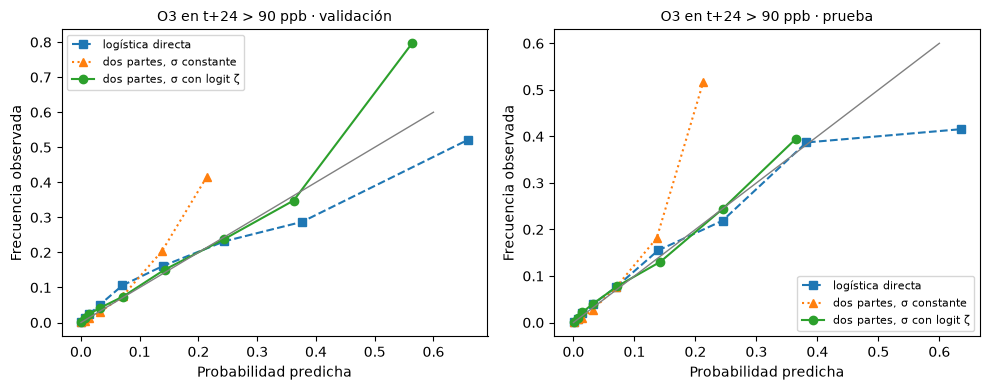

In [40]:
cortes = [0, .005, .01, .02, .05, .1, .2, .3, .5, 1]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, per in zip(ejes, ["validación", "prueba"]):
    t = juntar(per, ["y90"] + list(MODELOS90.values()))
    for nombre, marca in [("logística directa", "s--"), ("dos partes, σ constante", "^:"),
                          ("dos partes, σ con logit ζ", "o-")]:
        cal = calibracion(t["y90"], t[MODELOS90[nombre]], cortes)
        eje.plot(cal["pred"], cal["obs"], marca, label=nombre)
    eje.plot([0, .6], [0, .6], color="gray", lw=1)
    eje.set_xlabel("Probabilidad predicha")
    eje.set_ylabel("Frecuencia observada")
    eje.set_title(f"O3 en t+24 > {C:.0f} ppb · {per}", fontsize=10)
    eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_calibracion_norma.png", dpi=200)
plt.show()

Alertas por día

In [41]:
def por_dia(periodo):
    t = juntar(periodo, ["y90", "p90_final", "fecha_objetivo"])
    return t.groupby(["estacion", "fecha_objetivo"]).agg(y=("y90", "max"), p=("p90_final", "max"))


def alertas(y, p, tau):
    y = np.asarray(y, dtype=bool)
    alerta = np.asarray(p) >= tau
    return {"tau": tau, "alertas": int(alerta.sum()), "eventos": int(y.sum()),
            "aciertos": (alerta & y).sum() / y.sum(),
            "razón falsas alarmas": (alerta & ~y).sum() / alerta.sum()}


dia_2025 = por_dia("validación")
dia_2026 = por_dia("prueba")
print("AUC por día · 2025:", round(roc_auc_score(dia_2025["y"], dia_2025["p"]), 3),
      "| 2026:", round(roc_auc_score(dia_2026["y"], dia_2026["p"]), 3))

filas = []
for objetivo in [0.5, 0.7, 0.8]:
    # el corte más alto que todavía detecta el objetivo de días en 2025
    for tau in np.sort(dia_2025["p"].unique())[::-1]:
        if alertas(dia_2025["y"], dia_2025["p"], tau)["aciertos"] >= objetivo:
            break
    filas.append({"objetivo": objetivo, "periodo": "2025", **alertas(dia_2025["y"], dia_2025["p"], tau)})
    filas.append({"objetivo": objetivo, "periodo": "2026", **alertas(dia_2026["y"], dia_2026["p"], tau)})
pd.DataFrame(filas).round(3)

AUC por día · 2025: 0.801 | 2026: 0.808


,objetivo,periodo,tau,alertas,eventos,aciertos,razón falsas alarmas
0,0.5,2025,0.155,912,614,0.500,0.663
1,0.5,2026,0.155,457,348,0.466,0.646
2,0.7,2025,0.080,1570,614,0.700,0.726
3,0.7,2026,0.080,798,348,0.672,0.707
4,0.8,2025,0.045,2098,614,0.801,0.765
5,0.8,2026,0.045,1122,348,0.770,0.761


In [42]:
# Por estación en 2026
filas = []
for st in ESTACIONES:
    d = E[st]["pron"]
    t = d[d["periodo"] == "prueba"]
    filas.append({"estación": st, **metricas(t["y90"], t["p90_final"], t["p90_clima"])})
pd.DataFrame(filas).set_index("estación").round(3)

,n,eventos,brier,auc,bss
estación,,,,,
CE,4912,99,0.017,0.941,0.087
NE,4854,32,0.006,0.918,0.040
NE2,4751,6,0.001,0.798,-0.025
NE3,4707,8,0.002,0.901,0.004
NO,4222,51,0.011,0.935,0.077
NO2,5013,107,0.018,0.934,0.069
NO3,4546,35,0.007,0.943,0.029
NTE,4864,62,0.012,0.936,0.056
NTE2,5025,47,0.009,0.943,0.053


Parte 2 POR FIN MI PARTE YEII UNA DISCULPA
Pregunta: cuando la estación A está en un extremo, ¿qué tan probable es que B también?

Cada estación se pasa a escala uniforme con sus rangos, y se usan máximos diarios de 2023–2025. Como todas las estaciones tienen su temporada alta en los mismos meses, la estacionalidad común podría inflar chi; por eso también se calcula solo en temporada.

In [43]:
def chi_y_chibar(u1, u2, qs):
    ok = ~(np.isnan(u1) | np.isnan(u2))
    u1 = u1[ok]
    u2 = u2[ok]
    filas = []
    for q in qs:
        ambos = (u1 > q) & (u2 > q)
        p_ambos = ambos.mean()
        chi = p_ambos / (1 - q)
        chibar = 2 * np.log(1 - q) / np.log(p_ambos) - 1 if p_ambos > 0 else np.nan
        filas.append({"q": q, "chi": chi, "chibar": chibar, "n_conjunto": int(ambos.sum())})
    return pd.DataFrame(filas)


def bandas_bootstrap(u1, u2, qs, B=300, bloque=7):
    # Bootstrap de bloques de 7 días (los días seguidos dependen entre sí)
    rng = np.random.default_rng(0)
    n = len(u1)
    chis = []
    chibars = []
    for _ in range(B):
        inicios = rng.integers(0, n - bloque + 1, size=int(np.ceil(n / bloque)))
        indices = np.concatenate([np.arange(i, i + bloque) for i in inicios])[:n]
        c = chi_y_chibar(u1[indices], u2[indices], qs)
        chis.append(c["chi"].to_numpy())
        chibars.append(c["chibar"].to_numpy())
    return (np.nanpercentile(np.array(chis), [2.5, 97.5], axis=0),
            np.nanpercentile(np.array(chibars), [2.5, 97.5], axis=0))


def matriz_chi(Udatos, q):
    M = pd.DataFrame(np.eye(len(ESTACIONES)), index=ESTACIONES, columns=ESTACIONES)
    Mbar = M.copy()
    N = pd.DataFrame(0, index=ESTACIONES, columns=ESTACIONES)
    for i, a in enumerate(ESTACIONES):
        for b in ESTACIONES[i + 1:]:
            c = chi_y_chibar(Udatos[a].to_numpy(), Udatos[b].to_numpy(), [q]).iloc[0]
            M.loc[a, b] = M.loc[b, a] = c["chi"]
            Mbar.loc[a, b] = Mbar.loc[b, a] = c["chibar"]
            N.loc[a, b] = N.loc[b, a] = c["n_conjunto"]
    return M, Mbar, N


def distancia_km(a, b):
    lat1, lon1 = np.radians(COORDS.loc[a])
    lat2, lon2 = np.radians(COORDS.loc[b])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


def rumbo(a, b):
    # dirección de A hacia B en grados (0 = norte, 90 = este)
    lat1, lon1 = np.radians(COORDS.loc[a])
    lat2, lon2 = np.radians(COORDS.loc[b])
    y = np.sin(lon2 - lon1) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)
    return (np.degrees(np.arctan2(y, x)) + 360) % 360


def prueba_mantel(A, B, permutaciones=9999):
    rng = np.random.default_rng(0)
    arriba = np.triu_indices_from(A, 1)
    r_obs = np.corrcoef(A[arriba], B[arriba])[0, 1]
    mayores = 0
    for _ in range(permutaciones):
        orden = rng.permutation(A.shape[0])
        if np.corrcoef(A[np.ix_(orden, orden)][arriba], B[arriba])[0, 1] >= r_obs:
            mayores += 1
    return r_obs, (mayores + 1) / (permutaciones + 1)

In [44]:
# Máximo diario por estación (solo días con al menos 18 horas medidas)
horario = pd.DataFrame({st: E[st]["datos"][VAR] for st in ESTACIONES})
horas_medidas = horario.resample("D").count()
X = horario.resample("D").max().where(horas_medidas >= 18)
X = X[X.index < "2026-01-01"]

# Meses de temporada: al menos la mitad de los días > 90 del mes con más
por_mes = (X > C).sum(axis=1).groupby(X.index.month).sum()
TEMPORADA = list(por_mes[por_mes >= por_mes.max() * 0.5].index)
print("Estación-días con máximo > 90 por mes:", por_mes.to_dict())
print("Meses de temporada:", TEMPORADA)

U_todo = X.rank() / (X.notna().sum() + 1)
X_temp = X[X.index.month.isin(TEMPORADA)]
U_temp = X_temp.rank() / (X_temp.notna().sum() + 1)

# Viento de la ciudad: promedio diario de las componentes de todas las estaciones
uu = pd.DataFrame({st: E[st]["datos"]["wind_u"] for st in ESTACIONES}).mean(axis=1).resample("D").mean()
vv = pd.DataFrame({st: E[st]["datos"]["wind_v"] for st in ESTACIONES}).mean(axis=1).resample("D").mean()
viento_hacia = (np.degrees(np.arctan2(uu, vv)) + 360) % 360     # hacia dónde sopla
viento_hacia = viento_hacia.reindex(X.index)
print("Dirección media hacia donde sopla el viento:",
      round(float((np.degrees(np.arctan2(uu.mean(), vv.mean())) + 360) % 360), 1), "grados")

Estación-días con máximo > 90 por mes: {1: 10, 2: 129, 3: 167, 4: 153, 5: 252, 6: 190, 7: 102, 8: 79, 9: 114, 10: 118, 11: 132, 12: 16}
Meses de temporada: [2, 3, 4, 5, 6, 11]
Dirección media hacia donde sopla el viento: 275.4 grados


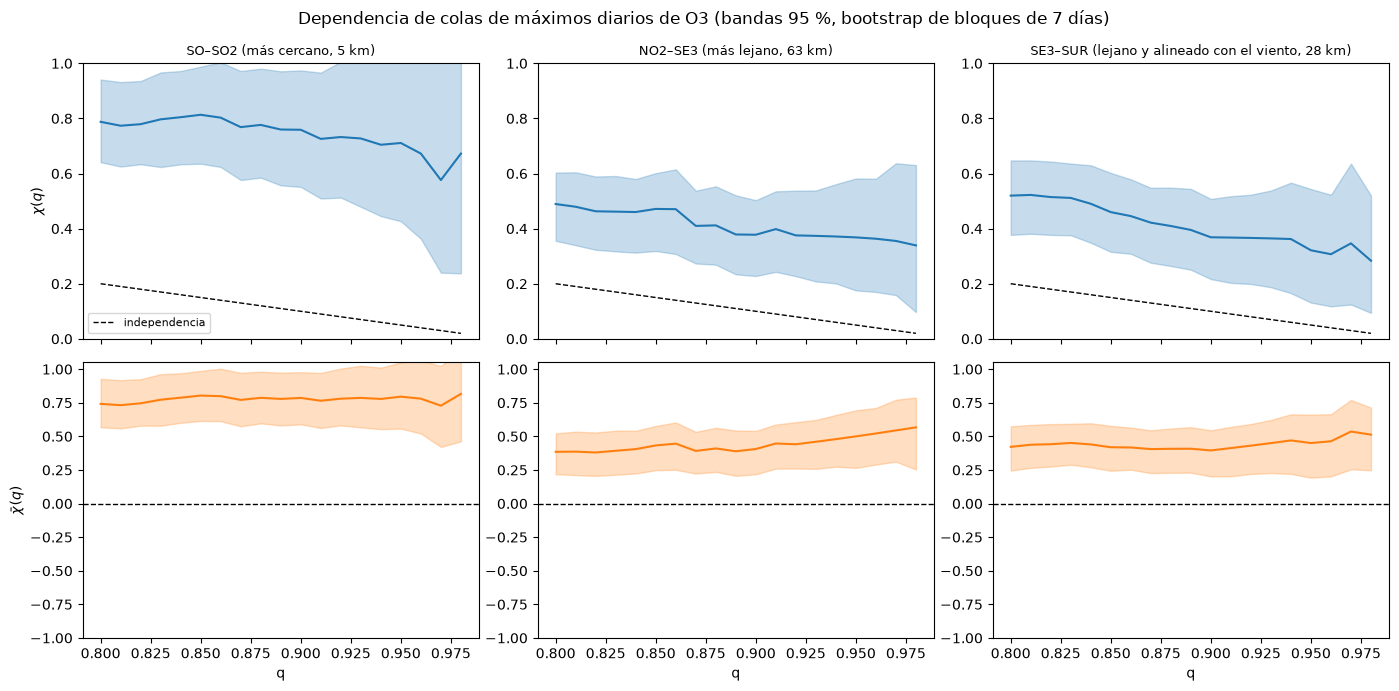

In [45]:
filas = []
for i, a in enumerate(ESTACIONES):
    for b in ESTACIONES[i + 1:]:
        r_ab = rumbo(a, b)
        filas.append({"a": a, "b": b, "distancia": distancia_km(a, b), "rumbo": r_ab,
                      "alineación": abs(np.cos(np.radians(viento_hacia - r_ab)).mean())})
pares = pd.DataFrame(filas)

cerca = pares.loc[pares["distancia"].idxmin()]
lejos = pares.loc[pares["distancia"].idxmax()]
lejanos = pares[pares["distancia"] > pares["distancia"].median()]
alineado = lejanos.loc[lejanos["alineación"].idxmax()]
EJEMPLOS = {"más cercano": cerca, "más lejano": lejos, "lejano y alineado con el viento": alineado}

qs = np.linspace(0.80, 0.98, 19)
fig, ejes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for j, (nombre, par) in enumerate(EJEMPLOS.items()):
    u1 = U_todo[par["a"]].to_numpy()
    u2 = U_todo[par["b"]].to_numpy()
    curva = chi_y_chibar(u1, u2, qs)
    banda_chi, banda_chibar = bandas_bootstrap(u1, u2, qs)
    ejes[0, j].plot(qs, curva["chi"], color="tab:blue")
    ejes[0, j].fill_between(qs, banda_chi[0], banda_chi[1], alpha=.25, color="tab:blue")
    ejes[0, j].plot(qs, 1 - qs, "k--", lw=1, label="independencia")
    ejes[0, j].set_ylim(0, 1)
    ejes[0, j].set_title(f"{par['a']}–{par['b']} ({nombre}, {par['distancia']:.0f} km)", fontsize=9)
    ejes[1, j].plot(qs, curva["chibar"], color="tab:orange")
    ejes[1, j].fill_between(qs, banda_chibar[0], banda_chibar[1], alpha=.25, color="tab:orange")
    ejes[1, j].axhline(0, color="k", ls="--", lw=1)
    ejes[1, j].set_ylim(-1, 1.05)
    ejes[1, j].set_xlabel("q")
ejes[0, 0].set_ylabel(r"$\chi(q)$")
ejes[1, 0].set_ylabel(r"$\bar\chi(q)$")
ejes[0, 0].legend(fontsize=8)
fig.suptitle("Dependencia de colas de máximos diarios de O3 (bandas 95 %, bootstrap de bloques de 7 días)")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_chi_pares.png", dpi=200)
plt.show()

Mínimo de días conjuntos en un par: 9


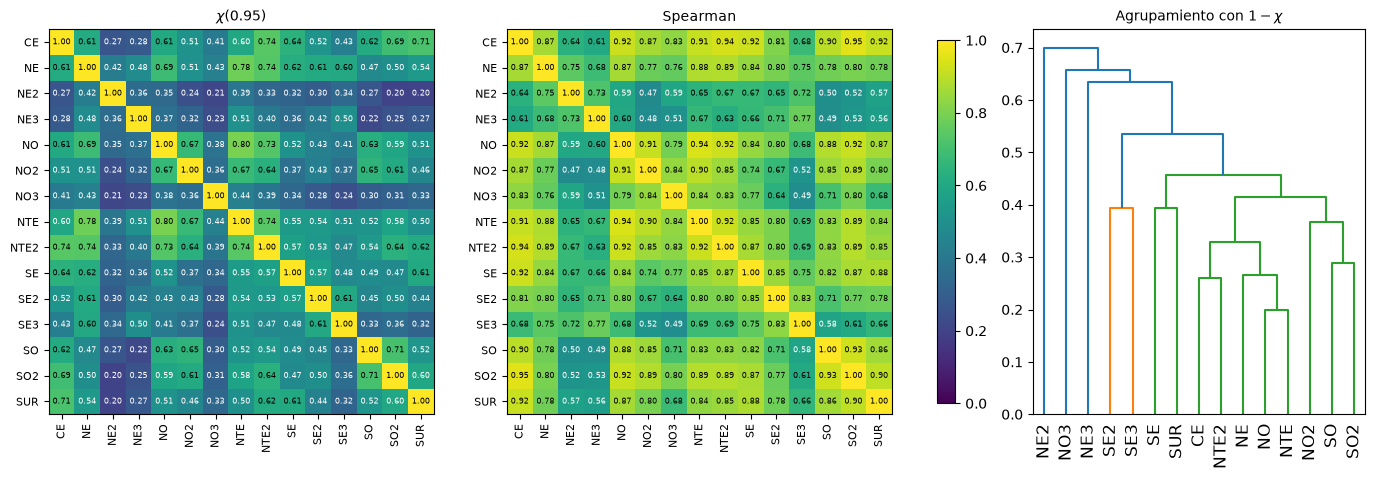

In [46]:
Q = 0.95
chi_M, chibar_M, n_conj = matriz_chi(U_todo, Q)
spearman = X.corr(method="spearman")
arriba = np.triu_indices(len(ESTACIONES), 1)
print("Mínimo de días conjuntos en un par:", int(n_conj.values[arriba].min()))

fig, ejes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for eje, M, titulo in [(ejes[0], chi_M, rf"$\chi({Q})$"), (ejes[1], spearman, "Spearman")]:
    im = eje.imshow(M.values, vmin=0, vmax=1, cmap="viridis")
    eje.set_xticks(range(len(M)))
    eje.set_xticklabels(M.columns, rotation=90, fontsize=8)
    eje.set_yticks(range(len(M)))
    eje.set_yticklabels(M.index, fontsize=8)
    for i in range(len(M)):
        for j in range(len(M)):
            color = "white" if M.values[i, j] < .6 else "black"
            eje.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color=color)
    eje.set_title(titulo, fontsize=10)
fig.colorbar(im, ax=ejes[:2], fraction=0.02)
D = 1 - chi_M.to_numpy()
np.fill_diagonal(D, 0)
dendrogram(linkage(squareform(D, checks=False), method="average"), labels=ESTACIONES,
           ax=ejes[2], leaf_rotation=90)
ejes[2].set_title(r"Agrupamiento con $1 - \chi$", fontsize=10)
fig.savefig(RUTA_FIGURAS + "final_chi_matriz.png", dpi=200, bbox_inches="tight")
plt.show()

Mantel (distancia vs 1 - chi): r = 0.531, p = 0.0005
chi medio: todo el año 0.476 | solo temporada 0.484


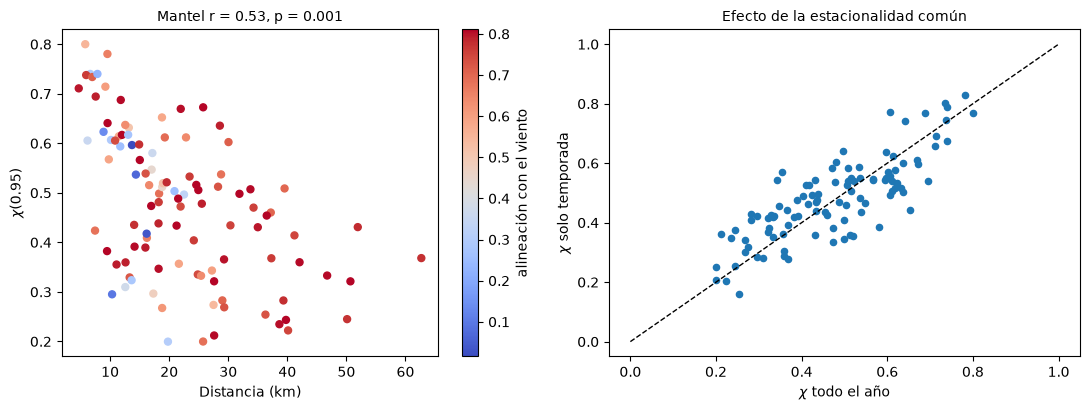

In [47]:
# Distancia, estacionalidad y viento
chi_todo = []
chi_temporada = []
for _, par in pares.iterrows():
    chi_todo.append(chi_M.loc[par["a"], par["b"]])
    c = chi_y_chibar(U_temp[par["a"]].to_numpy(), U_temp[par["b"]].to_numpy(), [Q]).iloc[0]
    chi_temporada.append(c["chi"])
pares["chi"] = chi_todo
pares["chi temporada"] = chi_temporada

distancias = np.array([[distancia_km(a, b) for b in ESTACIONES] for a in ESTACIONES])
r_m, p_m = prueba_mantel(distancias, 1 - chi_M.to_numpy())
print(f"Mantel (distancia vs 1 - chi): r = {r_m:.3f}, p = {p_m:.4f}")
print(f"chi medio: todo el año {pares['chi'].mean():.3f} | solo temporada {pares['chi temporada'].mean():.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
puntos = ejes[0].scatter(pares["distancia"], pares["chi"], c=pares["alineación"], cmap="coolwarm", s=25)
fig.colorbar(puntos, ax=ejes[0], label="alineación con el viento")
ejes[0].set_xlabel("Distancia (km)")
ejes[0].set_ylabel(rf"$\chi({Q})$")
ejes[0].set_title(f"Mantel r = {r_m:.2f}, p = {p_m:.3f}", fontsize=10)
ejes[1].scatter(pares["chi"], pares["chi temporada"], s=20)
ejes[1].plot([0, 1], [0, 1], "k--", lw=1)
ejes[1].set_xlabel(r"$\chi$ todo el año")
ejes[1].set_ylabel(r"$\chi$ solo temporada")
ejes[1].set_title("Efecto de la estacionalidad común", fontsize=10)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_chi_distancia.png", dpi=200)
plt.show()

chi condicionado al viento

El viento de la ciudad sopla casi siempre hacia el oeste. Para no mezclar viento con temporada, se
compara dentro de la temporada, días con viento de A hacia B (mas o menos 45°) contra los demás días de la
temporada, con q = 0.90. Cada par aparece en los dos sentidos, así que la prueba del signo es orientativa.

In [48]:
def chi_condicional(a, b, mascara, q):
    ua = U_todo[a].to_numpy()[mascara]
    ub = U_todo[b].to_numpy()[mascara]
    ok = ~(np.isnan(ua) | np.isnan(ub))
    extremo_a = ua[ok] > q
    extremo_b = ub[ok] > q
    ambos = (extremo_a & extremo_b).sum()
    return ambos / max(extremo_a.sum(), 1), int(ambos)


QV = 0.90
en_temporada = X.index.month.isin(TEMPORADA)
filas = []
for _, par in pares.iterrows():
    diferencia = np.abs((viento_hacia - par["rumbo"] + 180) % 360 - 180).to_numpy()
    for a, b, a_favor in [(par["a"], par["b"], diferencia < 45), (par["b"], par["a"], diferencia > 135)]:
        con_viento = en_temporada & a_favor
        sin_viento = en_temporada & ~a_favor & ~np.isnan(diferencia)
        chi_con, n_con = chi_condicional(a, b, con_viento, QV)
        chi_sin, n_sin = chi_condicional(a, b, sin_viento, QV)
        filas.append({"de": a, "hacia": b, "distancia": par["distancia"],
                      "chi a favor": chi_con, "n a favor": n_con, "chi resto": chi_sin, "n resto": n_sin})
cond = pd.DataFrame(filas)
cond = cond[(cond["n a favor"] >= 10) & (cond["n resto"] >= 10)].copy()
cond["diferencia"] = cond["chi a favor"] - cond["chi resto"]
positivos = int((cond["diferencia"] > 0).sum())
signo = binomtest(positivos, len(cond), 0.5)
print(f"chi es mayor con el viento a favor en {positivos} de {len(cond)} "
      f"(prueba del signo, p = {signo.pvalue:.3g})")
cond.sort_values("diferencia", ascending=False).round(3)

chi es mayor con el viento a favor en 8 de 10 (prueba del signo, p = 0.109)


,de,hacia,distancia,chi a favor,n a favor,chi resto,n resto,diferencia
1,NE,CE,11.475,0.800,16,0.521,25,0.279
157,SE,NTE,17.028,0.789,15,0.566,30,0.223
119,SUR,NO,18.818,0.842,16,0.651,28,0.191
50,NE,SO2,18.294,0.659,27,0.593,16,0.066
69,SE2,NE2,17.316,0.519,14,0.459,17,0.059
169,SE,NTE2,9.777,0.714,35,0.667,16,0.048
74,NE2,SO2,25.739,0.536,15,0.500,10,0.036
176,NTE2,SO2,12.564,0.806,29,0.786,33,0.020
27,SUR,CE,9.198,0.778,42,0.889,16,-0.111
29,NE2,NE,7.445,0.652,15,0.789,15,-0.137


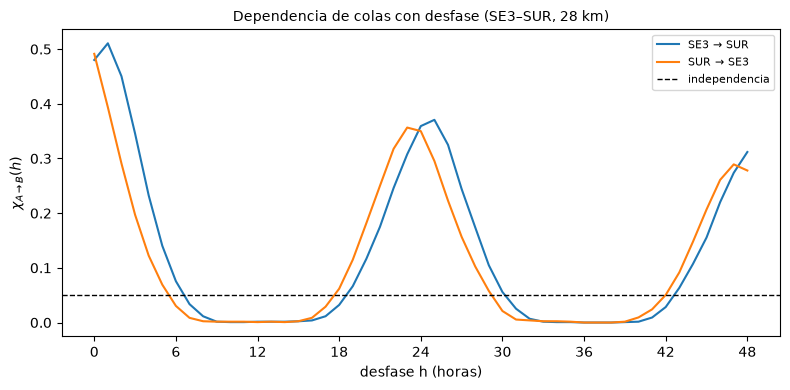

In [49]:
# chi con desfase
Xh = horario[horario.index < "2026-01-01"]
Uh = Xh.rank() / (Xh.notna().sum() + 1)


def chi_desfase(ua, ub, q, desfases):
    resultado = []
    for h in desfases:
        a = ua[:len(ua) - h] if h > 0 else ua
        b = ub[h:] if h > 0 else ub
        ok = ~(np.isnan(a) | np.isnan(b))
        resultado.append(np.mean((a[ok] > q) & (b[ok] > q)) / np.mean(a[ok] > q))
    return resultado


desfases = np.arange(0, 49)
par = EJEMPLOS["lejano y alineado con el viento"]
fig, eje = plt.subplots(figsize=(8, 4))
for a, b in [(par["a"], par["b"]), (par["b"], par["a"])]:
    eje.plot(desfases, chi_desfase(Uh[a].to_numpy(), Uh[b].to_numpy(), Q, desfases), label=f"{a} → {b}")
eje.axhline(1 - Q, color="k", ls="--", lw=1, label="independencia")
eje.set_xlabel("desfase h (horas)")
eje.set_ylabel(r"$\chi_{A \to B}(h)$")
eje.set_xticks(range(0, 49, 6))
eje.legend(fontsize=8)
eje.set_title(f"Dependencia de colas con desfase ({par['a']}–{par['b']}, {par['distancia']:.0f} km)", fontsize=10)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_chi_desfase.png", dpi=200)
plt.show()

Hay picos cada 24 h por el ciclo diario. Un extremo en SE3 (al este) va seguido
de uno en SUR una hora después ($\chi \approx 0.51$ en $h = 1$), mientras que en sentido contrario el
máximo está en $h = 0$. Con el viento hacia el oeste, es consistente con transporte de este a oeste,
aunque con un solo par es solo una pista.

Extensión, esto lo podemos quitar o no depende de cómo lo veanes  pronóstico meteorológico real y ozono de toda la ciudad. Los datos los saqué de una API de meteorología Open-Meto. solo me deja 10 consultas al día btw

El modelo final solo usa información medida hoy. Aquí se prueban dos fuentes nuevas, conocidas
también el día anterior:

Pronóstico meteorológico del día anterior (estos son los datos que generan la corrida del API y del pronóstico del programa de python de descargar_pronostico.py), basicamente lo que tiene es que  para cada hora de mañana, lo que el modelo meteorológico pronosticó un día antes,
   en un punto del centro de Monterrey. La temperatura está desde 2023; las demás variables, desde 2024.
Otras estaciones:

Ciudad:promedio del ozono actual (que es x_ciudad) y del máximo de 24 h (max24_ciudad) de las 15 estaciones
Viento arriba: promedio ponderado del ozono de las demás estaciones; pesa más si el viento sopla de
     esa estación hacia la nuestra y si está cerca, es basicamente esta formula para que la chequen:
     $w_j = \max(0, \cos(\text{viento} - \text{rumbo}_{j \to s})) \cdot e^{-d_{js}/d_0}$.
Formación del ozono: el ozono se forma cuando los precursores (NOx y compuestos orgánicos)
   reaccionan con el sol y el calor. Se agregan los precursores de hoy, que estan medidos por el SIMA: promedio de NOx y CO en las últimas 24 h. También cosnideré la nubosidad y radiación directa pronosticadas para la hora objetivo (Open-Meteo, desde 2024).
     Si mañana está nublado, no se forma ozono aunque haga calor.

Pensé que esto podría tener significancia para el modelo y más si nos preguntan sobre la meteorología ya podemos argumentar.

Como referencia se incluye también el clima que realmente hubo mañana (pronóstico perfecto), que es
el máximo que podría aportar un pronóstico. Todos los modelos de una tabla se comparan sobre las mismas
filas y la elección se hace en 2025.


In [50]:
# Leer el pronóstico (las primeras líneas del CSV son información del punto)
lineas = open("../data/pronostico_dia_anterior.csv", encoding="utf-8").read().splitlines()
inicio = 0
while not lineas[inicio].startswith("time"):
    inicio += 1
import io
pron = pd.read_csv(io.StringIO("\n".join(lineas[inicio:])))
pron.columns = ["time", "TOUT", "RH", "SR", "WSR", "WDR", "PRS", "RAINF"]
pron["time"] = pd.to_datetime(pron["time"])
pron = pron.set_index("time")
pron["SR"] = pron["SR"] / 1000            # W/m2 -> kW/m2 (como el SIMA)
pron["PRS"] = pron["PRS"] * 0.750062      # hPa -> mmHg (como el SIMA)

# Segundo archivo: nubosidad y radiación directa (las nubes bajas y la capa de mezcla vienen vacías)
lineas = open("../data/pronostico_extra.csv", encoding="utf-8").read().splitlines()
inicio = 0
while not lineas[inicio].startswith("time"):
    inicio += 1
extra = pd.read_csv(io.StringIO("\n".join(lineas[inicio:])))
extra.columns = ["time", "NUBES", "NUBES_BAJAS", "RAD_DIR", "CAPA"]
extra["time"] = pd.to_datetime(extra["time"])
extra = extra.set_index("time")
pron["NUBES"] = extra["NUBES"]
pron["RAD_DIR"] = extra["RAD_DIR"] / 1000  # W/m2 -> kW/m2

print("Fracción de horas con dato por año:")
print(pron.notna().groupby(pron.index.year).mean().round(2).T)
print("Nubes bajas y capa de mezcla con dato:", int(extra["NUBES_BAJAS"].notna().sum()), int(extra["CAPA"].notna().sum()))

# Comparación con la mediana de las 15 estaciones a esa hora
filas = []
for v in ["TOUT", "RH", "SR", "WSR", "PRS"]:
    observado = pd.DataFrame({st: E[st]["datos"][v] for st in ESTACIONES}).median(axis=1)
    juntos = pd.DataFrame({"pron": pron[v], "obs": observado}).dropna()
    error = juntos["pron"] - juntos["obs"]
    filas.append({"variable": v, "correlación": juntos["pron"].corr(juntos["obs"]),
                  "sesgo": error.mean(), "error típico (RMSE)": np.sqrt((error ** 2).mean())})
pd.DataFrame(filas).set_index("variable").round(3)

Fracción de horas con dato por año:
time     2023  2024  2025  2026
TOUT     0.99  0.95   1.0   1.0
RH       0.00  0.95   1.0   1.0
SR       0.00  0.95   1.0   1.0
WSR      0.00  0.95   1.0   1.0
WDR      0.00  0.95   1.0   1.0
PRS      0.00  0.95   1.0   1.0
RAINF    0.00  0.95   1.0   1.0
NUBES    0.00  0.95   1.0   1.0
RAD_DIR  0.00  0.95   1.0   1.0
Nubes bajas y capa de mezcla con dato: 0 0


,correlación,sesgo,error típico (RMSE)
variable,,,
TOUT,0.964,-0.286,1.895
RH,0.890,3.690,12.449
SR,0.945,0.089,0.170
WSR,0.724,1.824,4.795
PRS,0.913,-0.746,1.652


In [51]:
# Pronóstico en el espacio del ACP (mismas medias, desviaciones y vectores que el ACP del SIMA)
pron_acp = pron.copy()
pron_acp["RAINF"] = np.log1p(pron_acp["RAINF"])
pron_acp["WDR_sin"] = np.sin(np.deg2rad(pron_acp["WDR"]))
pron_acp["WDR_cos"] = np.cos(np.deg2rad(pron_acp["WDR"]))
puntajes = ((pron_acp[MET_ACP] - media_met) / desv_met).values @ vectores[:, :K] / np.sqrt(valores[:K])
PRON_CP = [c + "_pron" for c in CPS]
pron_cp = pd.DataFrame(puntajes, index=pron.index, columns=PRON_CP)

# Ozono de la ciudad y "viento arriba" (por hora)
u_hora = pd.DataFrame({st: E[st]["datos"]["wind_u"] for st in ESTACIONES}).mean(axis=1)
v_hora = pd.DataFrame({st: E[st]["datos"]["wind_v"] for st in ESTACIONES}).mean(axis=1)
viento_hora = (np.degrees(np.arctan2(u_hora, v_hora)) + 360) % 360
ozono = pd.DataFrame({st: E[st]["datos"][VAR] for st in ESTACIONES})
maximo24 = ozono.rolling(24, min_periods=12).max()
d0 = np.median([distancia_km(a, b) for a in ESTACIONES for b in ESTACIONES if a != b])

for st in ESTACIONES:
    s = E[st]["datos"]
    s["x_ciudad"] = ozono.mean(axis=1)
    s["max24_ciudad"] = maximo24.mean(axis=1)
    suma_x = 0
    suma_m = 0
    suma_w = 0
    for j in ESTACIONES:
        if j == st:
            continue
        w = np.clip(np.cos(np.radians(viento_hora - rumbo(j, st))), 0, None) * np.exp(-distancia_km(j, st) / d0)
        hay_dato = ozono[j].notna()
        suma_x = suma_x + (w * ozono[j]).where(hay_dato, 0)
        suma_m = suma_m + (w * maximo24[j]).where(maximo24[j].notna(), 0)
        suma_w = suma_w + w.where(hay_dato, 0)
    s["x_arriba"] = suma_x / suma_w.replace(0, np.nan)
    s["max24_arriba"] = suma_m / suma_w.replace(0, np.nan)

# Precursores: promedio de NOx y CO en las últimas 24 h (log, porque son muy sesgados).
# Si la estación no tiene dato, se usa la mediana de las demás estaciones a esa hora.
for v in ["NOX", "CO"]:
    promedio24 = pd.DataFrame({st: np.log1p(E[st]["datos"][v].rolling(24, min_periods=12).mean())
                               for st in ESTACIONES})
    mediana_ciudad = promedio24.median(axis=1)
    for st in ESTACIONES:
        E[st]["datos"][v + "_24"] = promedio24[st].fillna(mediana_ciudad)
        print(v, st, "relleno:", round(promedio24[st].isna().mean(), 2), end=" | ")
    print()


def tabla_extendida(st):
    # Tabla de pronóstico + variables nuevas, todas alineadas a la hora objetivo cuando corresponde
    s = E[st]["datos"]
    d = tabla_pronostico(s, H)
    objetivo = d.index + pd.Timedelta(hours=H)
    d["TOUT_pron"] = pron["TOUT"].reindex(objetivo).to_numpy()       # temperatura pronosticada para mañana
    for c in PRON_CP:
        d[c] = pron_cp[c].reindex(objetivo).to_numpy()               # pronóstico completo (ACP)
    d["NUBES_pron"] = pron["NUBES"].reindex(objetivo).to_numpy()     # nubosidad pronosticada
    d["RAD_DIR_pron"] = pron["RAD_DIR"].reindex(objetivo).to_numpy() # radiación directa pronosticada
    for c in ["NOX_24", "CO_24"]:
        d[c] = s[c]                                                   # precursores de hoy
    for c in CPS:
        d[c + "_real"] = s[c].shift(-H)                               # clima que realmente hubo mañana
    for c in ["x_ciudad", "max24_ciudad", "x_arriba", "max24_arriba"]:
        d[c] = s[c]
    return d


def evaluar_conjuntos(conjuntos, desde="2023-01-01"):
    todas = sorted(set(sum(conjuntos.values(), [])))
    guardar = {}
    for nombre in conjuntos:
        guardar[nombre] = {}
        for per in ["validación", "prueba"]:
            guardar[nombre][per] = {"y": [], "z": [], "ref": [], "y90": [], "p90": [], "ref90": [],
                                    "estacion": [], "fecha": [], "x": []}

    for st in ESTACIONES:
        d = tabla_extendida(st).dropna(subset=todas + ["y"])
        d = d[d.index >= desde]
        ent = d[d["periodo"] == "entrenamiento"]
        clima = ent.groupby(ent.index.hour)["y"].mean()
        clima90 = (ent["x_futuro"] > C).groupby(ent.index.hour).mean()
        for nombre, variables in conjuntos.items():
            m = ajustar_logit(ent, variables)
            zeta = predecir_logit(m, d)
            dd = d.copy()
            dd["logit_zeta"] = np.log(zeta / (1 - zeta))
            exc = dd[(dd["y"] == 1) & (dd["periodo"] == "entrenamiento")].copy()
            exc["y"] = exc["x_futuro"] - U
            m0 = ajustar_gpd(exc, [])
            mz = ajustar_gpd(exc, ["logit_zeta"], inicio=m0)
            p90 = zeta * prob_mayor_gpd(C - U, sigma_gpd(mz, dd), mz["params"][-1])
            for per in ["validación", "prueba"]:
                k = (d["periodo"] == per).to_numpy()
                g = guardar[nombre][per]
                g["y"].append(d["y"].to_numpy()[k])
                g["z"].append(zeta.to_numpy()[k])
                g["ref"].append(d.index.hour[k].map(clima).to_numpy())
                g["y90"].append((d["x_futuro"] > C).to_numpy()[k].astype(float))
                g["p90"].append(np.asarray(p90)[k])
                g["ref90"].append(d.index.hour[k].map(clima90).to_numpy())
                g["estacion"].append(np.full(k.sum(), st))
                g["fecha"].append(d["fecha_objetivo"].to_numpy()[k])
                g["x"].append(d["x_futuro"].to_numpy()[k])

    filas = []
    for nombre in conjuntos:
        for per in ["validación", "prueba"]:
            g = {q: np.concatenate(v) for q, v in guardar[nombre][per].items()}
            guardar[nombre][per] = g
            mz_ = metricas(g["y"], g["z"], g["ref"])
            m90 = metricas(g["y90"], g["p90"], g["ref90"])
            filas.append({"modelo": nombre, "periodo": per, "n": mz_["n"],
                          "AUC": mz_["auc"], "BSS": mz_["bss"],
                          "AUC P(>90)": m90["auc"], "BSS P(>90)": m90["bss"]})
    return pd.DataFrame(filas).set_index(["modelo", "periodo"]), guardar

NOX CE relleno: 0.04 | NOX NE relleno: 0.06 | NOX NE2 relleno: 0.17 | NOX NE3 relleno: 0.08 | NOX NO relleno: 0.13 | NOX NO2 relleno: 0.09 | NOX NO3 relleno: 0.25 | NOX NTE relleno: 0.01 | NOX NTE2 relleno: 0.0 | NOX SE relleno: 0.01 | NOX SE2 relleno: 0.03 | NOX SE3 relleno: 0.01 | NOX SO relleno: 0.04 | NOX SO2 relleno: 0.0 | NOX SUR relleno: 0.04 | 
CO CE relleno: 0.1 | CO NE relleno: 0.06 | CO NE2 relleno: 0.14 | CO NE3 relleno: 0.1 | CO NO relleno: 0.14 | CO NO2 relleno: 0.03 | CO NO3 relleno: 0.18 | CO NTE relleno: 0.03 | CO NTE2 relleno: 0.03 | CO SE relleno: 0.13 | CO SE2 relleno: 0.14 | CO SE3 relleno: 0.11 | CO SO relleno: 0.03 | CO SO2 relleno: 0.04 | CO SUR relleno: 0.07 | 


Entrenamiento 2023–2024: temperatura pronosticada y ozono de la ciudad

In [52]:
CIUDAD = ["x_ciudad", "max24_ciudad"]
ARRIBA = ["x_arriba", "max24_arriba"]
CONJUNTOS_A = {"modelo final": BASE,
               "+ ciudad": BASE + CIUDAD,
               "+ viento arriba": BASE + ARRIBA,
               "+ temperatura pronosticada": BASE + ["TOUT_pron"],
               "+ temperatura pronosticada + ciudad": BASE + ["TOUT_pron"] + CIUDAD}
tabla_a, predicciones_a = evaluar_conjuntos(CONJUNTOS_A)
tabla_a.round(4)

n     AUC     BSS  \
modelo                              periodo                              
modelo final                        validación  109439  0.9406  0.1559   
                                    prueba       67436  0.9422  0.1330   
+ ciudad                            validación  109439  0.9415  0.1612   
                                    prueba       67436  0.9430  0.1362   
+ viento arriba                     validación  109439  0.9410  0.1583   
                                    prueba       67436  0.9426  0.1325   
+ temperatura pronosticada          validación  109439  0.9506  0.2175   
                                    prueba       67436  0.9551  0.2097   
+ temperatura pronosticada + ciudad validación  109439  0.9517  0.2271   
                                    prueba       67436  0.9564  0.2158   

                                                AUC P(>90)  BSS P(>90)  
modelo                              periodo                             
modelo final                        validación      0.9517      0.1015  
                                    prueba          0.9495      0.0847  
+ ciudad                            validación      0.9531      0.1064  
                                    prueba          0.9501      0.0882  
+ viento arriba                     validación      0.9520      0.1036  
                                    prueba          0.9499      0.0856  
+ temperatura pronosticada          validación      0.9642      0.1473  
                                    prueba          0.9643      0.1344  
+ temperatura pronosticada + ciudad validación      0.9653      0.1530  
                                    prueba          0.9648      0.1356

 B. Entrenamiento solo 2024 pronóstico completo contra pronóstico perfecto
Las demás variables pronosticadas existen desde 2024, así que aquí todos los modelos se entrenan solo
con 2024 (por eso el modelo final da números un poco distintos a los de la Parte 1C).

In [53]:
CONJUNTOS_B = {"modelo final": BASE,
               "+ pronóstico completo (ACP)": BASE + PRON_CP,
               "+ clima real de mañana (perfecto)": BASE + [c + "_real" for c in CPS]}
tabla_b, _ = evaluar_conjuntos(CONJUNTOS_B, desde="2024-01-01")
tabla_b.round(4)

n     AUC     BSS  \
modelo                            periodo                              
modelo final                      validación  118066  0.9361  0.1327   
                                  prueba       72344  0.9393  0.1356   
+ pronóstico completo (ACP)       validación  118066  0.9417  0.1747   
                                  prueba       72344  0.9441  0.1660   
+ clima real de mañana (perfecto) validación  118066  0.9528  0.2391   
                                  prueba       72344  0.9545  0.2090   

                                              AUC P(>90)  BSS P(>90)  
modelo                            periodo                             
modelo final                      validación      0.9515      0.0920  
                                  prueba          0.9461      0.0906  
+ pronóstico completo (ACP)       validación      0.9584      0.1158  
                                  prueba          0.9559      0.1218  
+ clima real de mañana (perfecto) validación      0.9662      0.1422  
                                  prueba          0.9618      0.0941

In [54]:
# Alertas por día: modelo final contra modelo con temperatura pronosticada + ciudad
def alertas_por_dia(g):
    t = pd.DataFrame({"estacion": g["estacion"], "fecha": g["fecha"], "y": g["y90"], "p": g["p90"]})
    return t.groupby(["estacion", "fecha"]).agg(y=("y", "max"), p=("p", "max"))


filas = []
for nombre in ["modelo final", "+ temperatura pronosticada + ciudad"]:
    dia_2025 = alertas_por_dia(predicciones_a[nombre]["validación"])
    dia_2026 = alertas_por_dia(predicciones_a[nombre]["prueba"])
    for tau in np.sort(dia_2025["p"].unique())[::-1]:
        if alertas(dia_2025["y"], dia_2025["p"], tau)["aciertos"] >= 0.7:
            break
    for per, t in [("2025", dia_2025), ("2026", dia_2026)]:
        filas.append({"modelo": nombre, "periodo": per,
                      "AUC por día": roc_auc_score(t["y"], t["p"]), **alertas(t["y"], t["p"], tau)})
pd.DataFrame(filas).set_index(["modelo", "periodo"]).round(3)

AUC por día    tau  alertas  \
modelo                              periodo                                
modelo final                        2025           0.810  0.086     1488   
                                    2026           0.817  0.086      747   
+ temperatura pronosticada + ciudad 2025           0.856  0.097     1271   
                                    2026           0.873  0.097      645   

                                             eventos  aciertos  \
modelo                              periodo                      
modelo final                        2025         593     0.702   
                                    2026         339     0.664   
+ temperatura pronosticada + ciudad 2025         593     0.702   
                                    2026         339     0.684   

                                             razón falsas alarmas  
modelo                              periodo                        
modelo final                        2025                    0.720  
                                    2026                    0.699  
+ temperatura pronosticada + ciudad 2025                    0.673  
                                    2026                    0.640

C. Formación del ozono: precursores, nubosidad y radiación (entrenamiento solo 2024)
La nubosidad y la radiación pronosticadas existen desde 2024, así que, igual que en B, todos los modelos
se entrenan con 2024. Se parte del mejor modelo de A (temperatura pronosticada + ciudad).

In [55]:
PRECURSORES = ["NOX_24", "CO_24"]
NUBES = ["NUBES_pron", "RAD_DIR_pron"]
MEJOR_A = BASE + ["TOUT_pron"] + CIUDAD
CONJUNTOS_C = {"modelo final": BASE,
               "temp. pron. + ciudad": MEJOR_A,
               "+ precursores": MEJOR_A + PRECURSORES,
               "+ nubes y radiación": MEJOR_A + NUBES,
               "+ precursores + nubes y radiación": MEJOR_A + PRECURSORES + NUBES}
tabla_c, predicciones_c = evaluar_conjuntos(CONJUNTOS_C, desde="2024-01-01")
tabla_c.round(4)

n     AUC     BSS  \
modelo                            periodo                              
modelo final                      validación  118077  0.9361  0.1327   
                                  prueba       72357  0.9393  0.1356   
temp. pron. + ciudad              validación  118077  0.9463  0.1974   
                                  prueba       72357  0.9511  0.1947   
+ precursores                     validación  118077  0.9449  0.1832   
                                  prueba       72357  0.9479  0.1741   
+ nubes y radiación               validación  118077  0.9468  0.2029   
                                  prueba       72357  0.9514  0.1984   
+ precursores + nubes y radiación validación  118077  0.9452  0.1875   
                                  prueba       72357  0.9483  0.1800   

                                              AUC P(>90)  BSS P(>90)  
modelo                            periodo                             
modelo final                      validación      0.9515      0.0920  
                                  prueba          0.9462      0.0906  
temp. pron. + ciudad              validación      0.9643      0.1389  
                                  prueba          0.9617      0.1472  
+ precursores                     validación      0.9617      0.1329  
                                  prueba          0.9600      0.1389  
+ nubes y radiación               validación      0.9643      0.1420  
                                  prueba          0.9630      0.1511  
+ precursores + nubes y radiación validación      0.9616      0.1351  
                                  prueba          0.9607      0.1440

In [56]:
# Alertas por día de la tabla C (mismo procedimiento: corte para 70 % de aciertos en 2025)
filas = []
dias_c = {}
for nombre in CONJUNTOS_C:
    dia_2025 = alertas_por_dia(predicciones_c[nombre]["validación"])
    dia_2026 = alertas_por_dia(predicciones_c[nombre]["prueba"])
    for tau in np.sort(dia_2025["p"].unique())[::-1]:
        if alertas(dia_2025["y"], dia_2025["p"], tau)["aciertos"] >= 0.7:
            break
    dias_c[nombre] = (dia_2026, tau)
    for per, t in [("2025", dia_2025), ("2026", dia_2026)]:
        filas.append({"modelo": nombre, "periodo": per,
                      "AUC por día": roc_auc_score(t["y"], t["p"]), **alertas(t["y"], t["p"], tau)})
pd.DataFrame(filas).set_index(["modelo", "periodo"]).round(3)

AUC por día    tau  alertas  \
modelo                            periodo                                
modelo final                      2025           0.804  0.089     1478   
                                  2026           0.803  0.089      830   
temp. pron. + ciudad              2025           0.850  0.107     1279   
                                  2026           0.867  0.107      714   
+ precursores                     2025           0.845  0.096     1276   
                                  2026           0.860  0.096      758   
+ nubes y radiación               2025           0.853  0.105     1291   
                                  2026           0.871  0.105      729   
+ precursores + nubes y radiación 2025           0.848  0.098     1267   
                                  2026           0.864  0.098      742   

                                           eventos  aciertos  \
modelo                            periodo                      
modelo final                      2025         614     0.700   
                                  2026         348     0.661   
temp. pron. + ciudad              2025         614     0.700   
                                  2026         348     0.718   
+ precursores                     2025         614     0.700   
                                  2026         348     0.733   
+ nubes y radiación               2025         614     0.700   
                                  2026         348     0.724   
+ precursores + nubes y radiación 2025         614     0.700   
                                  2026         348     0.733   

                                           razón falsas alarmas  
modelo                            periodo                        
modelo final                      2025                    0.709  
                                  2026                    0.723  
temp. pron. + ciudad              2025                    0.664  
                                  2026                    0.650  
+ precursores                     2025                    0.663  
                                  2026                    0.664  
+ nubes y radiación               2025                    0.667  
                                  2026                    0.654  
+ precursores + nubes y radiación 2025                    0.661  
                                  2026                    0.656


Para cada alerta de 2026 que no terminó en exceso de 90, vemos qué máximo alcanzó el ozono ese día.

In [57]:
def maximo_por_dia(g):
    t = pd.DataFrame({"estacion": g["estacion"], "fecha": g["fecha"], "x": g["x"]})
    return t.groupby(["estacion", "fecha"])["x"].max()


filas = []
for nombre in ["modelo final", "temp. pron. + ciudad", "+ precursores + nubes y radiación"]:
    dia, tau = dias_c[nombre]
    maximo = maximo_por_dia(predicciones_c[nombre]["prueba"])
    falsas = maximo[(dia["p"] >= tau) & (dia["y"] == 0)]
    grupos = pd.cut(falsas, [-1, 50, 63, 80, 90], labels=["< 50", "50–63", "63–80", "80–90"])
    fila = grupos.value_counts(normalize=True).reindex(["< 50", "50–63", "63–80", "80–90"])
    fila["falsas alarmas"] = len(falsas)
    filas.append(fila.rename(nombre))
pd.DataFrame(filas).round(3)

x,< 50,50–63,63–80,80–90,falsas alarmas
modelo final,0.177,0.260,0.367,0.197,600.0
temp. pron. + ciudad,0.112,0.252,0.414,0.222,464.0
+ precursores + nubes y radiación,0.117,0.265,0.390,0.228,487.0



El pronóstico es bueno: la temperatura pronosticada un día antes tiene correlación 0.964 con la
  medida por el SIMA (error típico de 1.9 °C); viento y humedad son menos precisos.

  En cuanto a los hallazgos, una vez que se corre el código es la temperatura pronosticada es la mejora más grande sube el BSS de $P(X > 90)$ de 0.102 a 0.147 En 2025 y de 0.085 a 0.134 en 2026 (alrededor de 60 % más). Agregar el ozono de la ciudad suma un poco
  más (0.153 y 0.136). Es el mejor modelo en validación y lo confirma la prueba. (En esta tabla el modelo
  final da 0.102 y 0.085, y no 0.101 y 0.084, porque se evalúa en las horas donde existen todas las
  variables nuevas.). Poner otras estaciones solas ayudan poco, y ponderar por la dirección del viento aporta menos que el
  promedio simple de la ciudad.


En cuanto al pronóstico completo (entrenando con 2024), aquí también mejora al modelo final (0.091 a  0.122 en 2026)
  y en 2026 queda incluso arriba del "pronóstico perfecto" (0.094) que tiene más ruido si le quieren decir así. 
El AUC por día sube de 0.82 a 0.87 en 2026. Con el corte elegido en 2025 para detectar 70 % de los días, en 2026 detecta 68 % (antes 66 %) y la razón de falsas alarmas baja de 70 % a 64 %. La variable de previous_day1 es la corrida del modelo meteorológico de un día antes.


En cuanto a la formación del ozono (tabla C, entrenando con 2024)

Nubosidad y radiación pronosticadas: mejoran apenas el BSS de $P(X > 90)$ (0.139 a 0.142 en 2025,
  0.147 a 0.151 en 2026) y casi no cambian las alertas (falsas alarmas 65.0 % a 65.4 % en 2026).
  La temperatura pronosticada ya resume casi todo lo que dicen el sol y las nubes, por lo tanto podemos no considerarlo. 

Precursores (NOx y CO de hoy): empeoran el modelo (0.139 → 0.133 en 2025), así que no se agregan.
  Una explicación para esto que encontré en internet LOL, el NOx también destruye ozono cerca de donde se emite (titulación por NO), así
  que mucho NOx no siempre significa más ozono en la misma estación; además el ozono de hoy ya resume
  lo que hicieron los precursores. Faltan los compuestos orgánicos volátiles, que el SIMA no mide.
Las falsas alarmas no son días limpios como tal, con el mejor modelo, 22 % de las falsas alarmas de 2026
  llegaron a 80–90 ppb y 41 % a 63–80; solo 11 % se quedaron abajo de 50. Casi dos de cada tres alertas
  "falsas" fueron días con ozono arriba del umbral $u$ = 63.

Las nubes bajas y la altura de la capa de mezcla no vienen en el archivo de pronósticos anteriores, así que no se pudieron probar.

Apéndice: ¿cuánto se pierde al alertar con más anticipación? esto pues es una pregunta que se me ocurrió LOL 
Se repite el modelo final para horizontes de 1, 3, 6, 12 y 24 horas.

In [58]:
def evaluar_horizonte(h):
    resultados = {"validación": {"y": [], "z": [], "ref": [], "y90": [], "p90": [], "ref90": []},
                  "prueba": {"y": [], "z": [], "ref": [], "y90": [], "p90": [], "ref90": []}}
    for st in ESTACIONES:
        d = tabla_pronostico(E[st]["datos"], h).dropna(subset=BASE + ["y"])
        d["hora_objetivo"] = (d.index + pd.Timedelta(hours=h)).hour
        ent = d[d["periodo"] == "entrenamiento"]
        m = ajustar_logit(ent, BASE)
        d["zeta"] = predecir_logit(m, d)
        d["logit_zeta"] = np.log(d["zeta"] / (1 - d["zeta"]))
        clima = ent.groupby("hora_objetivo")["y"].mean()
        clima90 = (ent["x_futuro"] > C).groupby(ent["hora_objetivo"]).mean()
        exc = d[(d["y"] == 1) & (d["periodo"] == "entrenamiento")].copy()
        exc["y"] = exc["x_futuro"] - U
        m0 = ajustar_gpd(exc, [])
        mz = ajustar_gpd(exc, ["logit_zeta"], inicio=m0)
        d["p90"] = d["zeta"] * prob_mayor_gpd(C - U, sigma_gpd(mz, d), mz["params"][-1])
        for per in resultados:
            t = d[d["periodo"] == per]
            resultados[per]["y"].append(t["y"].to_numpy())
            resultados[per]["z"].append(t["zeta"].to_numpy())
            resultados[per]["ref"].append(t["hora_objetivo"].map(clima).to_numpy())
            resultados[per]["y90"].append((t["x_futuro"] > C).to_numpy().astype(float))
            resultados[per]["p90"].append(t["p90"].to_numpy())
            resultados[per]["ref90"].append(t["hora_objetivo"].map(clima90).to_numpy())
    filas = []
    for per, r in resultados.items():
        r = {k: np.concatenate(v) for k, v in r.items()}
        mz_ = metricas(r["y"], r["z"], r["ref"])
        m90 = metricas(r["y90"], r["p90"], r["ref90"])
        filas.append({"horizonte (h)": h, "periodo": per, "AUC": mz_["auc"], "BSS": mz_["bss"],
                      "AUC P(>90)": m90["auc"], "BSS P(>90)": m90["bss"]})
    return filas


filas = []
for h in [1, 3, 6, 12, 24]:
    filas += evaluar_horizonte(h)
pd.DataFrame(filas).set_index(["horizonte (h)", "periodo"]).round(3)

AUC    BSS  AUC P(>90)  BSS P(>90)
horizonte (h) periodo                                         
1             validación  0.989  0.623       0.993       0.411
              prueba      0.988  0.582       0.990       0.375
3             validación  0.962  0.304       0.971       0.169
              prueba      0.960  0.226       0.968       0.122
6             validación  0.946  0.192       0.955       0.112
              prueba      0.945  0.139       0.956       0.081
12            validación  0.943  0.162       0.951       0.101
              prueba      0.940  0.107       0.951       0.071
24            validación  0.940  0.157       0.952       0.101
              prueba      0.942  0.132       0.950       0.084

 A 1 hora el modelo parece excelente porque la concentración actual casi determina la
siguiente hora; eso es alerta inmediata, no temprana. La mejora cae hasta 6 horas y después se
estabiliza: 6, 12 y 24 horas dan casi lo mismo. Por eso se usa 24 h, que es la pregunta del proyecto. Por si querían validar esto ;)